# 01 — Data Preparation, EDA and Feature Engineering

This notebook prepares the telecommunications business-customer churn dataset for subsequent machine-learning analysis. It examines data quality, missing values, class imbalance and the distributions and relationships of relevant customer characteristics.

Data cleaning, exploratory data analysis and feature engineering are used to construct a consistent modelling dataset. The analysis also examines potentially redundant predictors and documents the decisions made during preprocessing and feature selection.

A stratified 80:20 training/test split is applied, with preprocessing fitted using the training data to reduce the risk of data leakage. Separate feature representations are prepared for the relevant model families, and class weights are calculated to support imbalance-aware modelling.

The resulting prepared datasets and preprocessing artefacts are saved for use in the subsequent model-development, evaluation and explainability notebooks. **No predictive models are trained or evaluated in this notebook.**

# 1. Environment Setup and Data Loading

In [ ]:
# Install Java and PySpark
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq
!pip install -q pyspark

import os
import sys

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PYSPARK_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("7005SCN_Data_cleaning_EDA")
    .config("spark.driver.memory", "8g")
    .config("spark.executor.memory", "4g")
    .config("spark.sql.shuffle.partitions", "200")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Session started:", spark.sparkContext.applicationId)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Spark version: 4.0.4
Session started: local-1788039832244


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import psutil
import subprocess

# Main dissertation folder
PROJECT = "/content/drive/MyDrive/7005SCN_Dissertation"

# Existing project folders
DATA = os.path.join(PROJECT, "dataset")
OUTPUTS = os.path.join(PROJECT, "outputs")
MODELS = os.path.join(PROJECT, "models")

# Dataset
CSV_PATH = os.path.join(DATA, "Baza_customer_Telecom_v2.csv")

# Check everything exists
print("Project folder exists:", os.path.exists(PROJECT))
print("Dataset folder exists:", os.path.exists(DATA))
print("Output folder exists:", os.path.exists(OUTPUTS))
print("Models folder exists:", os.path.exists(MODELS))
print("CSV file exists:", os.path.isfile(CSV_PATH))

# Show what is actually inside the dataset folder
print("\nFiles inside dataset folder:")
if os.path.exists(DATA):
    for file in os.listdir(DATA):
        print(" -", file)

# System information
print(f"\nRAM: {psutil.virtual_memory().total / 1e9:.1f} GB")

Project folder exists: True
Dataset folder exists: True
Output folder exists: True
Models folder exists: True
CSV file exists: True

Files inside dataset folder:
 - Baza_customer_Telecom_v2.csv

RAM: 13.6 GB


In [ ]:
CSV_PATH = f"{DATA}/Baza_customer_Telecom_v2.csv"
if os.path.exists(CSV_PATH):
 print(f"File present: {CSV_PATH}")

print("\n=== FILE SIZE VERIFICATION ===")
print(subprocess.run(["ls","-lh",DATA], capture_output=True, text=True).stdout)
sz  = os.path.getsize(CSV_PATH)/1e9
lc  = int(subprocess.run(["wc","-l",CSV_PATH],
           capture_output=True, text=True).stdout.strip().split()[0]) - 1
print(f"Data rows : {lc:,}")



File present: /content/drive/MyDrive/7005SCN_Dissertation/dataset/Baza_customer_Telecom_v2.csv

=== FILE SIZE VERIFICATION ===
total 532K
-rw------- 1 root root 532K Aug 15 23:10 Baza_customer_Telecom_v2.csv

Data rows : 8,453


In [ ]:
from pyspark.sql import functions as F

df_raw = spark.read.csv(CSV_PATH, header=True, inferSchema=True)
print(f"Total rows : {df_raw.count():,}")
print(f"Total cols : {len(df_raw.columns)}")
print()
print("=== df.printSchema() ===")
df_raw.printSchema()
print()
print("=== df.show(20) ===")
df_raw.show(20, truncate=True)

Total rows : 8,453
Total cols : 14

=== df.printSchema() ===
root
 |-- PID: string (nullable = true)
 |-- CRM_PID_Value_Segment: string (nullable = true)
 |-- EffectiveSegment: string (nullable = true)
 |-- Billing_ZIP: integer (nullable = true)
 |-- KA_name: string (nullable = true)
 |-- Active_subscribers: integer (nullable = true)
 |-- Not_Active_subscribers: integer (nullable = true)
 |-- Suspended_subscribers: integer (nullable = true)
 |-- Total_SUBs: integer (nullable = true)
 |-- AvgMobileRevenue : double (nullable = true)
 |-- AvgFIXRevenue: double (nullable = true)
 |-- TotalRevenue: double (nullable = true)
 |-- ARPU: double (nullable = true)
 |-- CHURN: string (nullable = true)


=== df.show(20) ===
+---------+---------------------+----------------+-----------+-------+------------------+----------------------+---------------------+----------+-----------------+-------------+------------+-----+-----+
|      PID|CRM_PID_Value_Segment|EffectiveSegment|Billing_ZIP|KA_name|Active

# 2. Data Understanding and Quality Assessment

In [ ]:
# ── Cell 6: Initial data quality audit ────────────────────────────────
# Purpose:
# 1. Examine the distribution of the target variable (CHURN)
# 2. Identify missing values across all columns

from pyspark.sql import functions as F
from pyspark.sql.functions import col, count, when, isnull

# ── 1. Target variable distribution ──────────────────────────────────
print("=== CHURN target distribution ===")

df_raw.groupBy("CHURN") \
      .count() \
      .orderBy("count", ascending=False) \
      .show()

# Calculate percentage distribution
total_rows = df_raw.count()

print("=== CHURN percentage distribution ===")

df_raw.groupBy("CHURN") \
      .count() \
      .withColumn(
          "percentage",
          F.round((col("count") / total_rows) * 100, 2)
      ) \
      .orderBy("count", ascending=False) \
      .show()


# ── 2. Missing-value audit ───────────────────────────────────────────
print("=== Missing values by column ===")

df_raw.select([
    count(when(isnull(c), c)).alias(c)
    for c in df_raw.columns
]).show(truncate=False)



=== CHURN target distribution ===
+-----+-----+
|CHURN|count|
+-----+-----+
|   No| 7904|
|  Yes|  549|
+-----+-----+

=== CHURN percentage distribution ===
+-----+-----+----------+
|CHURN|count|percentage|
+-----+-----+----------+
|   No| 7904|     93.51|
|  Yes|  549|      6.49|
+-----+-----+----------+

=== Missing values by column ===
+---+---------------------+----------------+-----------+-------+------------------+----------------------+---------------------+----------+-----------------+-------------+------------+----+-----+
|PID|CRM_PID_Value_Segment|EffectiveSegment|Billing_ZIP|KA_name|Active_subscribers|Not_Active_subscribers|Suspended_subscribers|Total_SUBs|AvgMobileRevenue |AvgFIXRevenue|TotalRevenue|ARPU|CHURN|
+---+---------------------+----------------+-----------+-------+------------------+----------------------+---------------------+----------+-----------------+-------------+------------+----+-----+
|0  |5                    |0               |2          |0      |0      

Initial observation: The target variable is highly imbalanced, with 93.51% of observations classified as non-churn and 6.49% as churn. This indicates that accuracy alone may provide a misleading assessment of model performance, supporting the use of additional classification metrics such as precision, recall, F1-score and ROC-AUC. The missing-value audit also identified substantial missingness in Suspended_subscribers and Not_Active_subscribers, requiring further investigation before determining an appropriate treatment.

In [ ]:
# ── Cell 7: Duplicate, uniqueness and categorical-value audit ─────────
# Purpose:
# 1. Check for duplicate rows
# 2. Check whether PID uniquely identifies each observation
# 3. Inspect the number of distinct values in every column
# 4. Inspect important categorical variables for unusual values

from pyspark.sql import functions as F


# ── 1. Check for completely duplicated rows ───────────────────────────

total_rows = df_raw.count()
unique_rows = df_raw.distinct().count()
duplicate_rows = total_rows - unique_rows

print("=== Duplicate row audit ===")
print(f"Total rows     : {total_rows}")
print(f"Unique rows    : {unique_rows}")
print(f"Duplicate rows : {duplicate_rows}")


# ── 2. Check whether PID is a unique identifier ───────────────────────

unique_pid = df_raw.select("PID").distinct().count()

print("\n=== PID uniqueness audit ===")
print(f"Total rows : {total_rows}")
print(f"Unique PID : {unique_pid}")
print(f"Duplicate PID values : {total_rows - unique_pid}")


# ── 3. Count distinct values in every column ──────────────────────────

print("\n=== Distinct values by column ===")

distinct_counts = df_raw.select([
    F.countDistinct(F.col(c)).alias(c)
    for c in df_raw.columns
])

distinct_counts.show(truncate=False)


# ── 4. Inspect categorical variables ──────────────────────────────────

categorical_columns = [
    "CRM_PID_Value_Segment",
    "EffectiveSegment",
    "KA_name",
    "CHURN"
]

for c in categorical_columns:
    print(f"\n=== Value distribution: {c} ===")

    df_raw.groupBy(c) \
          .count() \
          .orderBy(F.desc("count")) \
          .show(50, truncate=False)


=== Duplicate row audit ===
Total rows     : 8453
Unique rows    : 8453
Duplicate rows : 0

=== PID uniqueness audit ===
Total rows : 8453
Unique PID : 8436
Duplicate PID values : 17

=== Distinct values by column ===
+----+---------------------+----------------+-----------+-------+------------------+----------------------+---------------------+----------+-----------------+-------------+------------+----+-----+
|PID |CRM_PID_Value_Segment|EffectiveSegment|Billing_ZIP|KA_name|Active_subscribers|Not_Active_subscribers|Suspended_subscribers|Total_SUBs|AvgMobileRevenue |AvgFIXRevenue|TotalRevenue|ARPU|CHURN|
+----+---------------------+----------------+-----------+-------+------------------+----------------------+---------------------+----------+-----------------+-------------+------------+----+-----+
|8436|9                    |6               |456        |12     |61                |60                    |13                   |89        |2150             |106          |2163        |3063|2

Initial observation: No fully duplicated records were identified within the dataset. However, 8,436 unique PID values were observed across 8,453 records, indicating that some PID values appear more than once and require further investigation before any records are removed. Examination of categorical variables identified a likely data-entry inconsistency within CRM_PID_Value_Segment, where one observation was labelled Sliver compared with 2,039 observations labelled Silver. EffectiveSegment contained six categories with no missing values, while KA_name contained 12 categories. Billing_ZIP contained 456 distinct non-null values, indicating relatively high cardinality. These findings require further investigation before preprocessing decisions are made.

In [ ]:
# ── Cell 8: Investigate identified data-quality issues ────────────────
# Purpose:
# 1. Inspect records associated with duplicated PIDs
# 2. Inspect the suspected 'Sliver' typo
# 3. Inspect rows containing missing values in low-missingness variables
# 4. Examine Billing_ZIP at a high level

from pyspark.sql import functions as F


# ── 1. Identify duplicated PID values ────────────────────────────────

print("=== Records with duplicated PID values ===")

duplicate_pids = (
    df_raw.groupBy("PID")
          .count()
          .filter(F.col("count") > 1)
          .select("PID")
)

df_raw.join(duplicate_pids, on="PID", how="inner") \
      .orderBy("PID") \
      .show(50, truncate=False)


# ── 2. Inspect suspected typo in CRM_PID_Value_Segment ───────────────

print("\n=== Suspected 'Sliver' record ===")

df_raw.filter(
    F.col("CRM_PID_Value_Segment") == "Sliver"
).show(truncate=False)


# ── 3. Inspect rows containing small numbers of missing values ───────

print("\n=== Rows with missing CRM segment, Billing ZIP or ARPU ===")

df_raw.filter(
    F.col("CRM_PID_Value_Segment").isNull() |
    F.col("Billing_ZIP").isNull() |
    F.col("ARPU").isNull()
).show(truncate=False)


# ── 4. Billing ZIP summary ───────────────────────────────────────────

print("\n=== Billing_ZIP summary ===")

df_raw.select("Billing_ZIP").summary().show()

print(
    "Distinct Billing_ZIP values:",
    df_raw.select("Billing_ZIP").distinct().count()
)


=== Records with duplicated PID values ===
+--------+---------------------+----------------+-----------+-----------------+------------------+----------------------+---------------------+----------+-----------------+-------------+------------+-----+-----+
|PID     |CRM_PID_Value_Segment|EffectiveSegment|Billing_ZIP|KA_name          |Active_subscribers|Not_Active_subscribers|Suspended_subscribers|Total_SUBs|AvgMobileRevenue |AvgFIXRevenue|TotalRevenue|ARPU |CHURN|
+--------+---------------------+----------------+-----------+-----------------+------------------+----------------------+---------------------+----------+-----------------+-------------+------------+-----+-----+
|1.21E+12|Gold                 |SOHO            |6300       |RJ               |6                 |NULL                  |NULL                 |6         |182.17           |0.0          |182.17      |30.36|No   |
|1.21E+12|Silver               |SOHO            |4000       |Tatiana Trifonova|25                |NULL       

Further investigation: Inspection of the identified anomalies confirmed that the records sharing displayed PID values were not fully
duplicated observations and therefore should not be removed solely on this basis. The Sliver category appears once and is considered a
typographical inconsistency of the established Silver category, which will be corrected during data cleaning. The dataset documentation
confirms that PID represents the business customer's identification number and KA_name represents the customer's Key Account Manager. As
these variables function as identifiers rather than customer behavioural characteristics, they will be excluded from the predictive
modelling features. Billing_ZIP represents customer location and will be treated as categorical rather than continuous numerical
information. Further investigation is required before determining how the substantial missingness in Not_Active_subscribers and Suspended_subscribers should be handled.

# 3. Data Cleaning

In [ ]:
# ── Cell 9: Initial data cleaning ─────────────────────────────────────
# Purpose:
# 1. Create a cleaned working DataFrame while preserving df_raw
# 2. Correct the identified 'Sliver' category typo
# 3. Remove identifier-related variables not suitable for modelling
# 4. Verify the changes

from pyspark.sql import functions as F


# ── 1. Create working copy ────────────────────────────────────────────

df_clean = df_raw


# ── 2. Correct categorical inconsistency ──────────────────────────────

df_clean = df_clean.withColumn(
    "CRM_PID_Value_Segment",
    F.when(
        F.col("CRM_PID_Value_Segment") == "Sliver",
        "Silver"
    ).otherwise(F.col("CRM_PID_Value_Segment"))
)


# ── 3. Remove identifier-related variables ────────────────────────────

df_clean = df_clean.drop(
    "PID",
    "KA_name"
)


# ── 4. Verify changes ─────────────────────────────────────────────────

print("=== Cleaned dataset dimensions ===")
print(f"Rows: {df_clean.count()}")
print(f"Columns: {len(df_clean.columns)}")

print("\n=== Columns retained ===")
print(df_clean.columns)

print("\n=== CRM value segment after correction ===")

df_clean.groupBy("CRM_PID_Value_Segment") \
        .count() \
        .orderBy(F.desc("count")) \
        .show(truncate=False)

df_clean = df_clean.withColumnRenamed(
    "AvgMobileRevenue ",
    "AvgMobileRevenue"
)

print(df_clean.columns)


=== Cleaned dataset dimensions ===
Rows: 8453
Columns: 12

=== Columns retained ===
['CRM_PID_Value_Segment', 'EffectiveSegment', 'Billing_ZIP', 'Active_subscribers', 'Not_Active_subscribers', 'Suspended_subscribers', 'Total_SUBs', 'AvgMobileRevenue ', 'AvgFIXRevenue', 'TotalRevenue', 'ARPU', 'CHURN']

=== CRM value segment after correction ===
+---------------------+-----+
|CRM_PID_Value_Segment|count|
+---------------------+-----+
|Bronze               |3820 |
|Silver               |2040 |
|Gold                 |1453 |
|Platinum             |537  |
|SME                  |284  |
|Iron                 |246  |
|SE                   |41   |
|Lead                 |27   |
|NULL                 |5    |
+---------------------+-----+

['CRM_PID_Value_Segment', 'EffectiveSegment', 'Billing_ZIP', 'Active_subscribers', 'Not_Active_subscribers', 'Suspended_subscribers', 'Total_SUBs', 'AvgMobileRevenue', 'AvgFIXRevenue', 'TotalRevenue', 'ARPU', 'CHURN']


Initial cleaning: A separate working DataFrame (df_clean) was created to preserve the original imported dataset. The single Sliver value
identified during the data-quality audit was standardised to Silver as a categorical data-entry inconsistency. PID and KA_name were excluded
because the dataset documentation identifies these variables as the business customer identification number and Key Account Manager name
respectively. These identifier-related variables were not considered appropriate predictive features for the proposed customer churn models.
No observations were removed during this stage. The trailing whitespace identified in the AvgMobileRevenue column name was also removed to ensure consistent variable naming during subsequent analysis.

In [ ]:
# ── Cell 10: Investigate missing subscriber variables ─────────────────
# Purpose:
# 1. Examine missingness patterns in subscriber-count variables
# 2. Test the relationship between subscriber counts and Total_SUBs
# 3. Determine whether missing values may logically represent zero

from pyspark.sql import functions as F


# ── 1. Missingness combinations ───────────────────────────────────────

print("=== Missingness patterns ===")

df_clean.groupBy(
    F.col("Not_Active_subscribers").isNull().alias("Not_Active_missing"),
    F.col("Suspended_subscribers").isNull().alias("Suspended_missing")
).count().orderBy(F.desc("count")).show()


# ── 2. Compare Active + Not Active with Total Subscribers ─────────────

print("\n=== Active + Not Active compared with Total_SUBs ===")

df_clean.withColumn(
    "subscriber_difference",
    F.col("Total_SUBs") -
    (
        F.col("Active_subscribers") +
        F.coalesce(F.col("Not_Active_subscribers"), F.lit(0))
    )
).groupBy("subscriber_difference") \
 .count() \
 .orderBy(F.desc("count")) \
 .show(30, truncate=False)


# ── 3. Examine rows where Not_Active_subscribers is missing ───────────

print("\n=== When Not_Active_subscribers is missing ===")

df_clean.filter(
    F.col("Not_Active_subscribers").isNull()
).select(
    "Active_subscribers",
    "Not_Active_subscribers",
    "Suspended_subscribers",
    "Total_SUBs"
).show(30, truncate=False)


# ── 4. Examine rows where Suspended_subscribers is present ────────────

print("\n=== When Suspended_subscribers is present ===")

df_clean.filter(
    F.col("Suspended_subscribers").isNotNull()
).select(
    "Active_subscribers",
    "Not_Active_subscribers",
    "Suspended_subscribers",
    "Total_SUBs",
    "CHURN"
).show(30, truncate=False)


# ── 5. Verify full subscriber-count relationship ──────────────────────

print("\n=== Verify subscriber-count relationship ===")

subscriber_check = df_clean.withColumn(
    "calculated_total",
    F.col("Active_subscribers") +
    F.coalesce(F.col("Not_Active_subscribers"), F.lit(0)) +
    F.coalesce(F.col("Suspended_subscribers"), F.lit(0))
).withColumn(
    "difference",
    F.col("Total_SUBs") - F.col("calculated_total")
)

subscriber_check.groupBy("difference") \
                .count() \
                .orderBy(F.desc("count")) \
                .show(30, truncate=False)

=== Missingness patterns ===
+------------------+-----------------+-----+
|Not_Active_missing|Suspended_missing|count|
+------------------+-----------------+-----+
|             false|             true| 4086|
|              true|             true| 4015|
|             false|            false|  218|
|              true|            false|  134|
+------------------+-----------------+-----+


=== Active + Not Active compared with Total_SUBs ===
+---------------------+-----+
|subscriber_difference|count|
+---------------------+-----+
|0                    |8101 |
|1                    |286  |
|2                    |33   |
|3                    |11   |
|6                    |5    |
|4                    |4    |
|5                    |3    |
|7                    |3    |
|9                    |2    |
|22                   |1    |
|13                   |1    |
|17                   |1    |
|8                    |1    |
|10                   |1    |
+---------------------+-----+


=== When Not_A

Missing subscriber investigation: The missing values within Not_Active_subscribers and Suspended_subscribers were investigated before imputation. Using zero in place of the missing values for diagnostic purposes demonstrated that Total_SUBs was equal to the sum of Active_subscribers, Not_Active_subscribers and Suspended_subscribers for all 8,453 observations. This indicates that the null values in these subscriber-count variables represent the absence of subscribers within the respective categories rather than unknown observations. Therefore,replacing these null values with zero is considered appropriate and preserves the internal consistency of the dataset.

In [ ]:
# ── Cell 11: Handle structural missing values ─────────────────────────
# Purpose:
# Replace null subscriber counts with zero following the
# relationship established during the data-quality investigation.

from pyspark.sql import functions as F


# ── 1. Replace structural nulls with zero ─────────────────────────────

df_clean = df_clean.fillna({
    "Not_Active_subscribers": 0,
    "Suspended_subscribers": 0
})


# ── 2. Verify that the nulls have been removed ────────────────────────

print("=== Missing subscriber values after cleaning ===")

df_clean.select(
    F.sum(F.col("Not_Active_subscribers").isNull().cast("int"))
        .alias("Not_Active_missing"),
    F.sum(F.col("Suspended_subscribers").isNull().cast("int"))
        .alias("Suspended_missing")
).show()


# ── 3. Re-check subscriber-count consistency ──────────────────────────

print("\n=== Subscriber-count consistency after cleaning ===")

df_clean.withColumn(
    "calculated_total",
    F.col("Active_subscribers") +
    F.col("Not_Active_subscribers") +
    F.col("Suspended_subscribers")
).withColumn(
    "difference",
    F.col("Total_SUBs") - F.col("calculated_total")
).groupBy("difference") \
 .count() \
 .orderBy(F.desc("count")) \
 .show()


# ── 4. Check remaining missing values ─────────────────────────────────

print("\n=== Remaining missing values ===")

df_clean.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df_clean.columns
]).show(truncate=False)


=== Missing subscriber values after cleaning ===
+------------------+-----------------+
|Not_Active_missing|Suspended_missing|
+------------------+-----------------+
|                 0|                0|
+------------------+-----------------+


=== Subscriber-count consistency after cleaning ===
+----------+-----+
|difference|count|
+----------+-----+
|         0| 8453|
+----------+-----+


=== Remaining missing values ===
+---------------------+----------------+-----------+------------------+----------------------+---------------------+----------+----------------+-------------+------------+----+-----+
|CRM_PID_Value_Segment|EffectiveSegment|Billing_ZIP|Active_subscribers|Not_Active_subscribers|Suspended_subscribers|Total_SUBs|AvgMobileRevenue|AvgFIXRevenue|TotalRevenue|ARPU|CHURN|
+---------------------+----------------+-----------+------------------+----------------------+---------------------+----------+----------------+-------------+------------+----+-----+
|5                    |

Structural missing-value treatment: Null values in Not_Active_subscribers and Suspended_subscribers were replaced with zero following the relationship established during the preceding data-quality investigation. Verification after replacement confirmed that no missing values remained in either variable and that Total_SUBs continued to equal the sum of active, non-active and suspended subscribers for all 8 453 observations. This treatment therefore preserved the internal consistency of the subscriber-count variables without removing any observations.

In [ ]:
# ── Cell 12: Investigate ARPU calculation ─────────────────────────────
# Purpose:
# 1. Determine how ARPU relates to the revenue/subscriber variables
# 2. Assess whether the single missing ARPU value can be reconstructed
#    from existing information

from pyspark.sql import functions as F


# ── 1. Compare ARPU with possible revenue-per-subscriber calculations ─

arpu_check = df_clean.filter(
    F.col("ARPU").isNotNull()
).select(
    "ARPU",
    "AvgMobileRevenue",
    "AvgFIXRevenue",
    "TotalRevenue",
    "Active_subscribers",
    "Total_SUBs"
).withColumn(
    "TotalRevenue_per_Active",
    F.round(
        F.col("TotalRevenue") / F.col("Active_subscribers"),
        2
    )
).withColumn(
    "TotalRevenue_per_TotalSUBs",
    F.round(
        F.col("TotalRevenue") / F.col("Total_SUBs"),
        2
    )
)


# ── 2. Measure agreement with the recorded ARPU ───────────────────────

print("=== ARPU calculation comparison ===")

arpu_check.select(
    F.round(
        F.avg(
            F.abs(F.col("ARPU") - F.col("TotalRevenue_per_Active"))
        ), 4
    ).alias("Mean_difference_using_active"),

    F.round(
        F.avg(
            F.abs(F.col("ARPU") - F.col("TotalRevenue_per_TotalSUBs"))
        ), 4
    ).alias("Mean_difference_using_total")
).show()


# ── 3. Display examples for manual inspection ─────────────────────────

print("\n=== Example ARPU calculations ===")

arpu_check.show(20, truncate=False)


# ── 4. Display the record with missing ARPU ───────────────────────────

print("\n=== Record with missing ARPU ===")

df_clean.filter(
    F.col("ARPU").isNull()
).show(truncate=False)



=== ARPU calculation comparison ===
+----------------------------+---------------------------+
|Mean_difference_using_active|Mean_difference_using_total|
+----------------------------+---------------------------+
|                      0.3006|                     5.4097|
+----------------------------+---------------------------+


=== Example ARPU calculations ===
+-----+----------------+-------------+------------+------------------+----------+-----------------------+--------------------------+
|ARPU |AvgMobileRevenue|AvgFIXRevenue|TotalRevenue|Active_subscribers|Total_SUBs|TotalRevenue_per_Active|TotalRevenue_per_TotalSUBs|
+-----+----------------+-------------+------------+------------------+----------+-----------------------+--------------------------+
|13.39|40.17           |0.0          |40.17       |3                 |3         |13.39                  |13.39                     |
|20.09|40.17           |0.0          |40.17       |2                 |5         |20.09               

ARPU investigation: The single missing ARPU value was investigated using the revenue and subscriber variables. Comparison of the recorded
ARPU values indicated that ARPU is closely associated with TotalRevenue divided by Active_subscribers, with a substantially smaller mean  absolute difference (0.3006) than when using total subscribers (5.4097). For the observation containing the missing ARPU value, TotalRevenue was 40.17 and there were two active subscribers, producing a calculated ARPU of 20.085 (20.09 when rounded to two decimal places). This provides a data-supported basis for reconstructing the missing value rather than removing the observation.

In [ ]:
# ── Cell 13: Complete missing-value treatment ─────────────────────────
# Purpose:
# 1. Reconstruct the single missing ARPU value
# 2. Retain observations with unknown CRM segment / Billing ZIP
# 3. Verify that no missing values remain

from pyspark.sql import functions as F


# ── 1. Reconstruct missing ARPU ───────────────────────────────────────

df_clean = df_clean.withColumn(
    "ARPU",
    F.when(
        F.col("ARPU").isNull(),
        F.round(
            F.col("TotalRevenue") / F.col("Active_subscribers"),
            2
        )
    ).otherwise(F.col("ARPU"))
)


# ── 2. Handle unknown categorical values ──────────────────────────────

df_clean = df_clean.fillna({
    "CRM_PID_Value_Segment": "Unknown"
})

# Billing_ZIP is currently numeric, so use a temporary sentinel value.
# Its treatment as a categorical geographical variable will be addressed
# during feature preprocessing.
df_clean = df_clean.fillna({
    "Billing_ZIP": -1
})


# ── 3. Final missing-value audit ──────────────────────────────────────

print("=== Missing values after cleaning ===")

df_clean.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df_clean.columns
]).show(truncate=False)


# ── 4. Verify reconstructed ARPU ──────────────────────────────────────

print("\n=== Verify reconstructed ARPU ===")

df_clean.filter(
    (F.col("TotalRevenue") == 40.17) &
    (F.col("Active_subscribers") == 2)
).select(
    "TotalRevenue",
    "Active_subscribers",
    "ARPU"
).show()


# ── 5. Verify unknown categories ──────────────────────────────────────

print("\n=== CRM segment after missing-value treatment ===")

df_clean.groupBy("CRM_PID_Value_Segment") \
        .count() \
        .orderBy(F.desc("count")) \
        .show()


=== Missing values after cleaning ===
+---------------------+----------------+-----------+------------------+----------------------+---------------------+----------+----------------+-------------+------------+----+-----+
|CRM_PID_Value_Segment|EffectiveSegment|Billing_ZIP|Active_subscribers|Not_Active_subscribers|Suspended_subscribers|Total_SUBs|AvgMobileRevenue|AvgFIXRevenue|TotalRevenue|ARPU|CHURN|
+---------------------+----------------+-----------+------------------+----------------------+---------------------+----------+----------------+-------------+------------+----+-----+
|0                    |0               |0          |0                 |0                     |0                    |0         |0               |0            |0           |0   |0    |
+---------------------+----------------+-----------+------------------+----------------------+---------------------+----------+----------------+-------------+------------+----+-----+


=== Verify reconstructed ARPU ===
+----------

Completion of missing-value treatment: The single missing ARPU value was reconstructed as 20.09 using the relationship between TotalRevenue and Active_subscribers identified during the preceding investigation. The five missing CRM_PID_Value_Segment values were retained as an Unknown category rather than assigning customers to an unsupported value segment. The two missing Billing_ZIP values were temporarily represented using a sentinel value of -1 to preserve the observations while the geographical variable remains numeric. Billing_ZIP will subsequently be evaluated as a categorical feature during exploratory analysis and feature preprocessing. A final missing-value audit confirmed that no null values remained within the working dataset.

# 4. Exploratory Data Analysis

In [ ]:
# ── Cell 14: Descriptive statistics for numerical variables ──────────
# Purpose:
# 1. Summarise the numerical features in the cleaned dataset
# 2. Examine their ranges, averages and variability
# 3. Identify variables that may require further investigation during EDA

numerical_columns = [
    "Active_subscribers",
    "Not_Active_subscribers",
    "Suspended_subscribers",
    "Total_SUBs",
    "AvgMobileRevenue",
    "AvgFIXRevenue",
    "TotalRevenue",
    "ARPU"
]

print("=== Descriptive statistics for numerical variables ===")

df_clean.select(numerical_columns).summary(
    "count",
    "mean",
    "stddev",
    "min",
    "25%",
    "50%",
    "75%",
    "max"
).show(truncate=False)

=== Descriptive statistics for numerical variables ===
+-------+------------------+----------------------+---------------------+------------------+------------------+------------------+------------------+-----------------+
|summary|Active_subscribers|Not_Active_subscribers|Suspended_subscribers|Total_SUBs        |AvgMobileRevenue  |AvgFIXRevenue     |TotalRevenue      |ARPU             |
+-------+------------------+----------------------+---------------------+------------------+------------------+------------------+------------------+-----------------+
|count  |8453              |8453                  |8453                 |8453              |8453              |8453              |8453              |8453             |
|mean   |7.774636223825861 |2.1198391103750147    |0.0656571631373477   |9.960132497338224 |148.01195551875142|0.8211853779723175|148.83314089672382|24.44127410386865|
|stddev |6.6805238713900605|7.065473691027901     |0.5118751052148448   |10.246648042247948|102.570538582

Numerical feature summary: Descriptive statistics confirmed 8,453 complete observations across all numerical variables following data cleaning. Several subscriber and revenue variables displayed evidence of positive skew, with maximum values substantially exceeding their respective medians and upper quartiles. For example, Total_SUBs had a median of 7 and an upper quartile of 12, compared with a maximum of 235. These extreme values were not automatically treated as errors because the dataset contains businesses of different sizes and may therefore legitimately include organisations with substantially larger subscriber bases. AvgFIXRevenue displayed a particularly high concentration of zero values, with the 25th, 50th and 75th percentiles all equal to zero. ARPU also showed a wide range, from 0 to 462.83. These distributions require further graphical investigation before determining whether any observations represent problematic outliers.

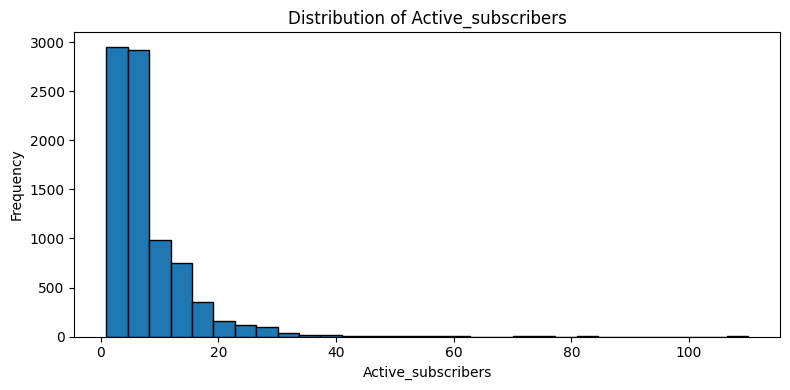

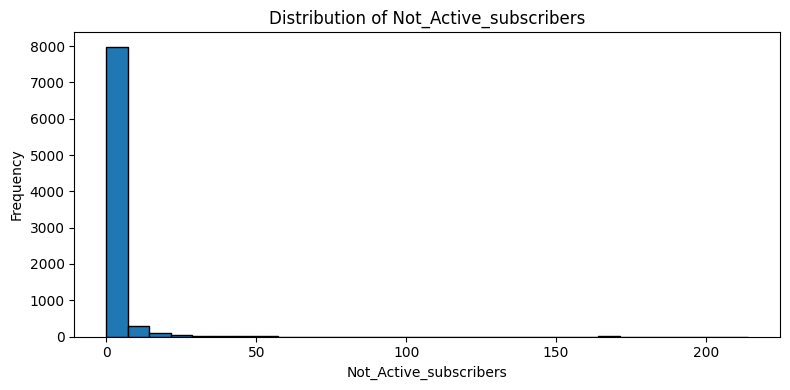

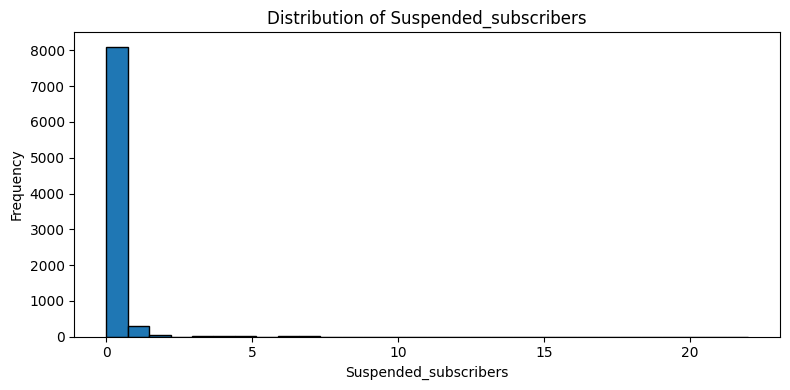

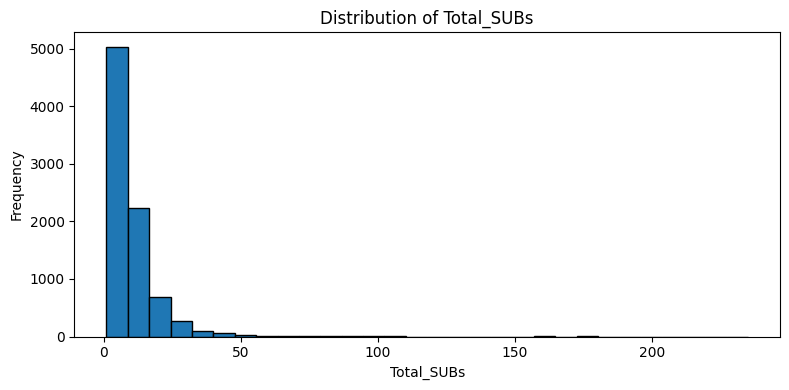

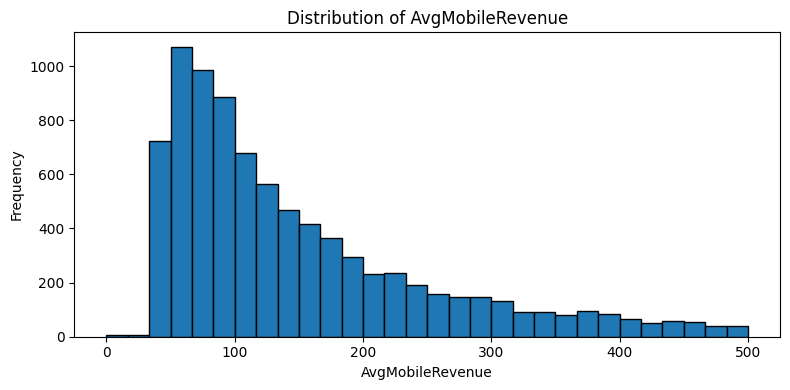

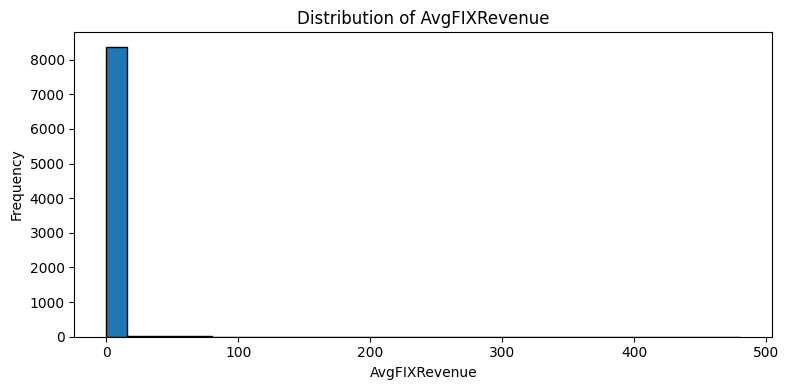

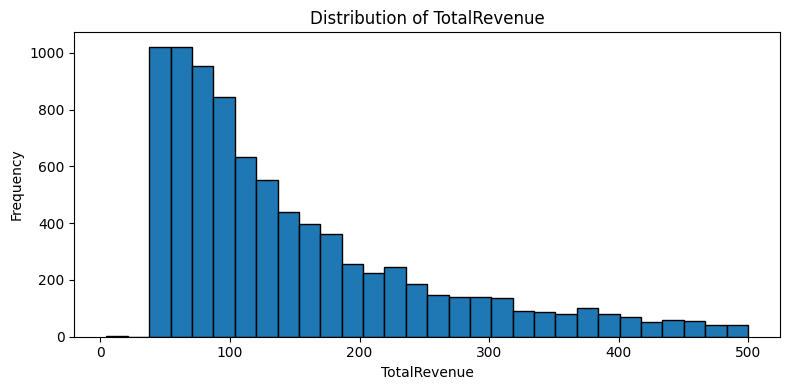

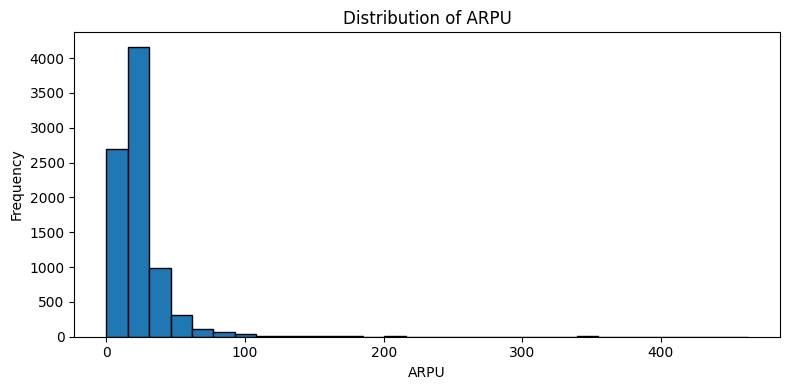

In [ ]:
# ── Cell 15: Numerical feature distributions ──────────────────────────
# Purpose:
# 1. Visualise the distributions of numerical features
# 2. Identify skewness, concentration and potential extreme values
# 3. Support later preprocessing and feature-selection decisions

import matplotlib.pyplot as plt

# Convert selected numerical variables to Pandas for plotting
numeric_pd = df_clean.select(numerical_columns).toPandas()

# Plot each numerical variable separately
for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    plt.hist(
        numeric_pd[column],
        bins=30,
        edgecolor="black"
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

Numerical distributions: Most numerical variables were positively skewed, with subscriber counts concentrated among smaller businesses and a few substantially larger observations. Not_Active_subscribers and Suspended_subscribers had many zero values, while AvgFIXRevenue was strongly zero-inflated. AvgMobileRevenue and TotalRevenue showed similar right-skewed distributions, suggesting a relationship worth investigating. ARPU was also right-skewed. Extreme values were retained because there was no evidence that they were invalid, and differences in business size could explain some of the variation.


=== Distribution of CRM_PID_Value_Segment ===
CRM_PID_Value_Segment  count
               Bronze   3820
               Silver   2040
                 Gold   1453
             Platinum    537
                  SME    284
                 Iron    246
                   SE     41
                 Lead     27
              Unknown      5


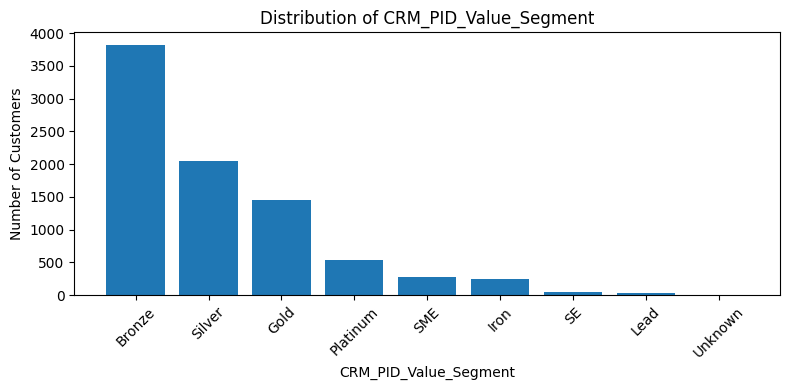


=== Distribution of EffectiveSegment ===
EffectiveSegment  count
            SOHO   6301
             VSE   1795
             SME    284
              SE     42
           Other     29
              LE      2


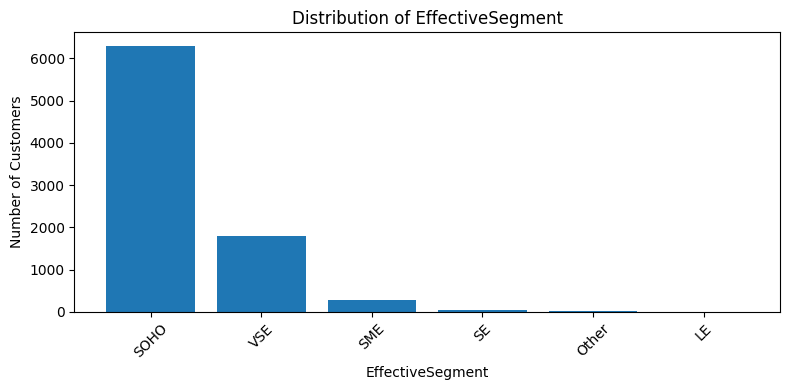

In [ ]:
# ── Cell 16: Categorical feature distributions ────────────────────────
# Purpose:
# 1. Examine the distribution of customers across CRM value segments
# 2. Examine the distribution of customers across effective segments
# 3. Identify dominant or under-represented categories

import matplotlib.pyplot as plt


categorical_columns = [
    "CRM_PID_Value_Segment",
    "EffectiveSegment"
]


for column in categorical_columns:

    # Calculate category frequencies using PySpark
    category_counts = (
        df_clean.groupBy(column)
                .count()
                .orderBy("count", ascending=False)
                .toPandas()
    )

    # Display frequency table
    print(f"\n=== Distribution of {column} ===")
    print(category_counts.to_string(index=False))

    # Plot category frequencies
    plt.figure(figsize=(8, 4))

    plt.bar(
        category_counts[column].astype(str),
        category_counts["count"]
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

Categorical feature distributions: The customer segmentation variables displayed substantial class imbalance. CRM_PID_Value_Segment was dominated by Bronze, Silver and Gold customers, which collectively represented the majority of observations, while categories including SE, Lead and Unknown were comparatively rare. EffectiveSegment was particularly concentrated within the SOHO category, which represented approximately 74.5% of customers, followed by VSE at approximately 21.2%. SME, SE, Other and LE contained substantially fewer observations. These differences in category size should be considered when interpreting subsequent churn-rate comparisons, as high or low churn rates within very small categories may be based on insufficient observations to indicate a reliable pattern.


=== Churn rate by CRM_PID_Value_Segment ===
+---------------------+---------------+-----------------+------------------+
|CRM_PID_Value_Segment|Total_Customers|Churned_Customers|Churn_Rate_Percent|
+---------------------+---------------+-----------------+------------------+
|SME                  |284            |25               |8.8               |
|Platinum             |537            |46               |8.57              |
|Gold                 |1453           |117              |8.05              |
|Silver               |2040           |146              |7.16              |
|Bronze               |3820           |205              |5.37              |
|Iron                 |246            |9                |3.66              |
|SE                   |41             |1                |2.44              |
|Lead                 |27             |0                |0.0               |
|Unknown              |5              |0                |0.0               |
+---------------------+--------

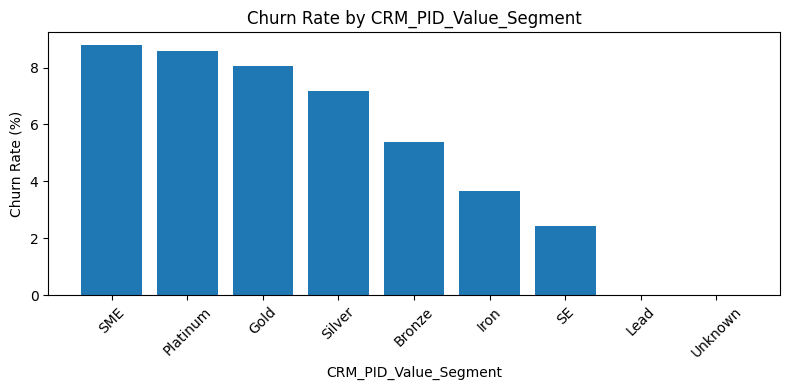


=== Churn rate by EffectiveSegment ===
+----------------+---------------+-----------------+------------------+
|EffectiveSegment|Total_Customers|Churned_Customers|Churn_Rate_Percent|
+----------------+---------------+-----------------+------------------+
|VSE             |1795           |159              |8.86              |
|SME             |284            |25               |8.8               |
|Other           |29             |2                |6.9               |
|SOHO            |6301           |362              |5.75              |
|SE              |42             |1                |2.38              |
|LE              |2              |0                |0.0               |
+----------------+---------------+-----------------+------------------+



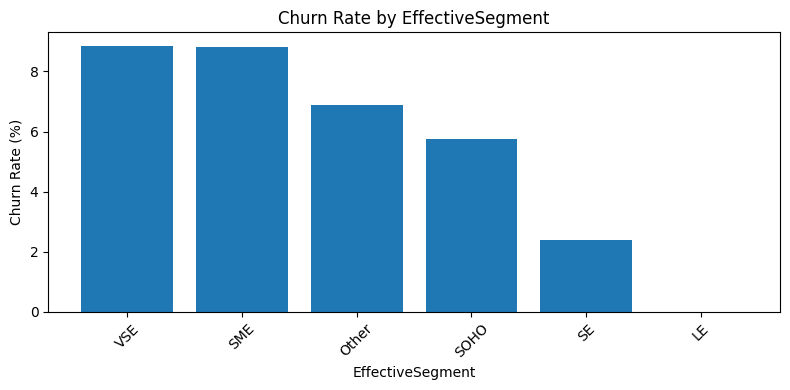

In [ ]:
# ── Cell 17: Churn rate by customer segment ───────────────────────────
# Purpose:
# 1. Compare churn rates across CRM value segments
# 2. Compare churn rates across effective customer segments
# 3. Consider category size when interpreting churn differences

from pyspark.sql import functions as F
import matplotlib.pyplot as plt


categorical_columns = [
    "CRM_PID_Value_Segment",
    "EffectiveSegment"
]


for column in categorical_columns:

    # Calculate total customers and churned customers per category
    churn_by_segment = (
        df_clean.groupBy(column)
        .agg(
            F.count("*").alias("Total_Customers"),
            F.sum(
                F.when(F.col("CHURN") == "Yes", 1).otherwise(0)
            ).alias("Churned_Customers")
        )
        .withColumn(
            "Churn_Rate_Percent",
            F.round(
                (F.col("Churned_Customers") /
                 F.col("Total_Customers")) * 100,
                2
            )
        )
        .orderBy(F.desc("Churn_Rate_Percent"))
    )


    # Display results
    print(f"\n=== Churn rate by {column} ===")

    churn_by_segment.show(truncate=False)


    # Convert aggregated results only to Pandas for plotting
    churn_segment_pd = churn_by_segment.toPandas()


    # Plot churn rate
    plt.figure(figsize=(8, 4))

    plt.bar(
        churn_segment_pd[column].astype(str),
        churn_segment_pd["Churn_Rate_Percent"]
    )

    plt.title(f"Churn Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

Churn across customer segments: Churn rates varied across both customer segmentation variables. Within CRM_PID_Value_Segment, SME customers displayed the highest observed churn rate (8.80%), followed by Platinum (8.57%) and Gold (8.05%), compared with an overall dataset churn rate of 6.49%. Bronze and Iron customers showed lower observed churn rates of 5.37% and 3.66%, respectively. Within EffectiveSegment, VSE and SME customers displayed the highest churn rates at 8.86% and 8.80%, while the dominant SOHO segment had a lower rate of 5.75%. Rates associated with very small categories, including Lead, Unknown and LE, should be interpreted cautiously because they are based on relatively few observations. Overall, the descriptive analysis indicates that customer segmentation may contain useful information for distinguishing churn behaviour, although these relationships do not establish causation or statistical significance.

In [ ]:
# ── Cell 18: Numerical features by churn status ───────────────────────
# Purpose:
# 1. Compare numerical characteristics of churned and retained customers
# 2. Identify potential differences associated with churn
# 3. Guide subsequent visual and predictive analysis

from pyspark.sql import functions as F


print("=== Numerical feature averages by churn status ===")

churn_numerical_summary = (
    df_clean.groupBy("CHURN")
    .agg(
        F.count("*").alias("Customers"),

        F.round(F.avg("Active_subscribers"), 2)
         .alias("Avg_Active_Subscribers"),

        F.round(F.avg("Not_Active_subscribers"), 2)
         .alias("Avg_Not_Active_Subscribers"),

        F.round(F.avg("Suspended_subscribers"), 2)
         .alias("Avg_Suspended_Subscribers"),

        F.round(F.avg("Total_SUBs"), 2)
         .alias("Avg_Total_SUBs"),

        F.round(F.avg("AvgMobileRevenue"), 2)
         .alias("Avg_Mobile_Revenue"),

        F.round(F.avg("AvgFIXRevenue"), 2)
         .alias("Avg_FIX_Revenue"),

        F.round(F.avg("TotalRevenue"), 2)
         .alias("Avg_Total_Revenue"),

        F.round(F.avg("ARPU"), 2)
         .alias("Avg_ARPU")
    )
)

churn_numerical_summary.show(truncate=False)

=== Numerical feature averages by churn status ===
+-----+---------+----------------------+--------------------------+-------------------------+--------------+------------------+---------------+-----------------+--------+
|CHURN|Customers|Avg_Active_Subscribers|Avg_Not_Active_Subscribers|Avg_Suspended_Subscribers|Avg_Total_SUBs|Avg_Mobile_Revenue|Avg_FIX_Revenue|Avg_Total_Revenue|Avg_ARPU|
+-----+---------+----------------------+--------------------------+-------------------------+--------------+------------------+---------------+-----------------+--------+
|No   |7904     |7.67                  |2.11                      |0.06                     |9.84          |146.25            |0.85           |147.1            |24.4    |
|Yes  |549      |9.34                  |2.3                       |0.09                     |11.72         |173.33            |0.48           |173.81           |25.0    |
+-----+---------+----------------------+--------------------------+-------------------------+-

Numerical characteristics by churn status: Churned customers displayed higher average values across several subscriber and revenue measures. Churners had an average of 9.34 active subscribers and 11.72 total subscribers, compared with 7.67 and 9.84 respectively among non-churners. Average mobile revenue and total revenue were also higher among churned customers, at 173.33 and 173.81 respectively, compared with 146.25 and 147.10 among retained customers. In contrast, average ARPU was similar between the groups (25.00 for churners and 24.40 for non-churners), while average fixed revenue was slightly lower among churners. These descriptive differences suggest that subscriber volume and revenue-related characteristics may be associated with churn; however, the numerical distributions are positively skewed, meaning that averages may be influenced by extreme observations. Median-based comparisons are therefore required before drawing stronger conclusions.

In [ ]:
# ── Cell 19: Median numerical features by churn status ────────────────
# Purpose:
# 1. Compare median numerical characteristics of churned and retained customers
# 2. Reduce the influence of extreme values identified during EDA
# 3. Determine whether the patterns observed in the means remain present

from pyspark.sql import functions as F


print("=== Numerical feature medians by churn status ===")

churn_median_summary = (
    df_clean.groupBy("CHURN")
    .agg(
        F.count("*").alias("Customers"),

        F.percentile_approx("Active_subscribers", 0.5)
         .alias("Median_Active_Subscribers"),

        F.percentile_approx("Not_Active_subscribers", 0.5)
         .alias("Median_Not_Active_Subscribers"),

        F.percentile_approx("Suspended_subscribers", 0.5)
         .alias("Median_Suspended_Subscribers"),

        F.percentile_approx("Total_SUBs", 0.5)
         .alias("Median_Total_SUBs"),

        F.round(
            F.percentile_approx("AvgMobileRevenue", 0.5), 2
        ).alias("Median_Mobile_Revenue"),

        F.round(
            F.percentile_approx("AvgFIXRevenue", 0.5), 2
        ).alias("Median_FIX_Revenue"),

        F.round(
            F.percentile_approx("TotalRevenue", 0.5), 2
        ).alias("Median_Total_Revenue"),

        F.round(
            F.percentile_approx("ARPU", 0.5), 2
        ).alias("Median_ARPU")
    )
)

churn_median_summary.show(truncate=False)

=== Numerical feature medians by churn status ===
+-----+---------+-------------------------+-----------------------------+----------------------------+-----------------+---------------------+------------------+--------------------+-----------+
|CHURN|Customers|Median_Active_Subscribers|Median_Not_Active_Subscribers|Median_Suspended_Subscribers|Median_Total_SUBs|Median_Mobile_Revenue|Median_FIX_Revenue|Median_Total_Revenue|Median_ARPU|
+-----+---------+-------------------------+-----------------------------+----------------------------+-----------------+---------------------+------------------+--------------------+-----------+
|No   |7904     |6                        |1                            |0                           |7                |111.17               |0.0               |111.67              |19.31      |
|Yes  |549      |7                        |1                            |0                           |9                |140.17               |0.0               |140.17   

Median comparison by churn status: Median comparisons supported the earlier mean-based findings while reducing the influence of extreme observations. Churned customers had higher median active subscribers (7 vs 6), total subscribers (9 vs 7), mobile revenue (140.17 vs 111.17) and total revenue (140.17 vs 111.67). However, median ARPU was similar between churned and retained customers (19.23 vs 19.31), while both groups had median fixed revenue and suspended subscriber counts of zero. The consistent subscriber and revenue differences suggest these patterns were not solely driven by extreme values. Higher total revenue among churners may therefore partly reflect their larger subscriber bases rather than greater revenue per active subscriber.

=== Numerical feature correlation matrix ===
                        Active_subscribers  Not_Active_subscribers  \
Active_subscribers                   1.000                   0.099   
Not_Active_subscribers               0.099                   1.000   
Suspended_subscribers                0.038                   0.086   
Total_SUBs                           0.722                   0.758   
AvgMobileRevenue                     0.701                   0.126   
AvgFIXRevenue                       -0.003                   0.098   
TotalRevenue                         0.696                   0.136   
ARPU                                -0.276                   0.088   

                        Suspended_subscribers  Total_SUBs  AvgMobileRevenue  \
Active_subscribers                      0.038       0.722             0.701   
Not_Active_subscribers                  0.086       0.758             0.126   
Suspended_subscribers                   1.000       0.134             0.096   
Total_SU

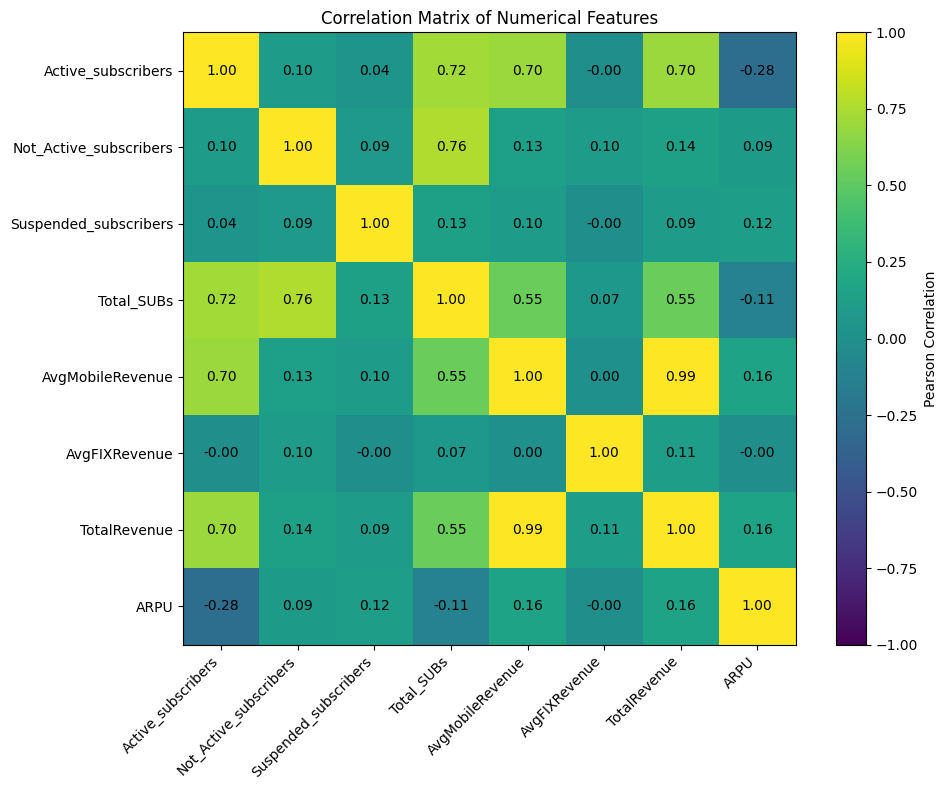

In [ ]:
# ── Cell 20: Numerical feature correlation analysis ───────────────────
# Purpose:
# 1. Measure relationships between numerical features
# 2. Identify strongly correlated or potentially redundant variables
# 3. Support later feature-selection decisions

import matplotlib.pyplot as plt
import numpy as np


# ── 1. Calculate correlation matrix ───────────────────────────────────

correlation_matrix = numeric_pd[numerical_columns].corr()

print("=== Numerical feature correlation matrix ===")
print(correlation_matrix.round(3))


# ── 2. Plot correlation heatmap ───────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1
)

# Axis labels
ax.set_xticks(np.arange(len(numerical_columns)))
ax.set_yticks(np.arange(len(numerical_columns)))

ax.set_xticklabels(numerical_columns, rotation=45, ha="right")
ax.set_yticklabels(numerical_columns)

# Display correlation values inside cells
for i in range(len(numerical_columns)):
    for j in range(len(numerical_columns)):
        ax.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Correlation Matrix of Numerical Features")

fig.colorbar(
    heatmap,
    ax=ax,
    label="Pearson Correlation"
)

plt.tight_layout()
plt.show()

Correlation and feature redundancy: The correlation analysis identified several important relationships between the numerical predictors. AvgMobileRevenue and TotalRevenue exhibited an extremely strong positive correlation (r = 0.994), indicating substantial redundancy between these variables. This is consistent with the dataset structure, as total revenue incorporates mobile and fixed-service revenue while fixed-service revenue is zero for the majority of customers. Total_SUBs was also strongly correlated with both Not_Active_subscribers (r = 0.758) and Active_subscribers (r = 0.722). These relationships are expected because the earlier data-quality analysis established that total subscribers are mathematically derived from active, non-active and suspended subscriber counts. Active subscribers additionally showed moderately strong positive relationships with mobile revenue (r = 0.701) and total revenue (r = 0.696), suggesting that businesses with larger active subscriber bases generally generate greater revenue. In contrast, ARPU showed relatively weak relationships with most revenue and subscriber measures. These findings identify potential feature redundancy that will be considered during feature engineering and selection rather than removing variables during the exploratory analysis stage.

Cell 14: numerical descriptive statistics
Cell 15: numerical distributions/skewness
Cell 16: categorical distributions
Cell 17: churn rates across customer segments
Cell 18: mean numerical characteristics by churn
Cell 19: median numerical characteristics by churn
Cell 20: correlations and potential predictor redundancy

/tmp/ipykernel_7800/2799436438.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


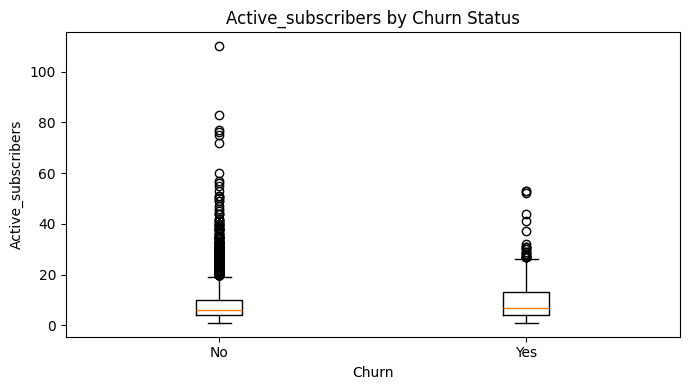

/tmp/ipykernel_7800/2799436438.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


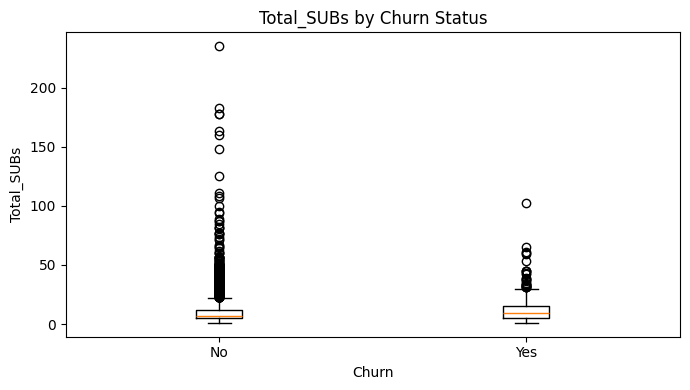

/tmp/ipykernel_7800/2799436438.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


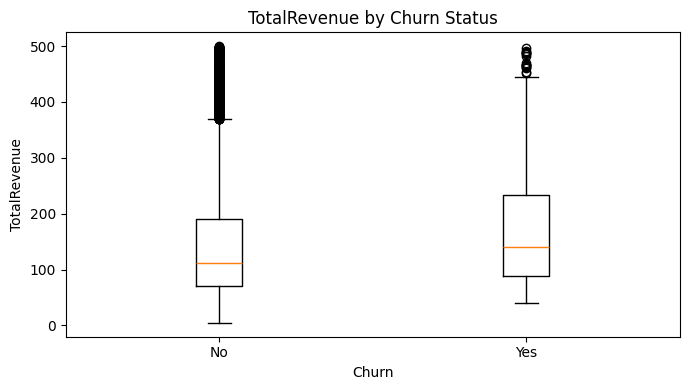

/tmp/ipykernel_7800/2799436438.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


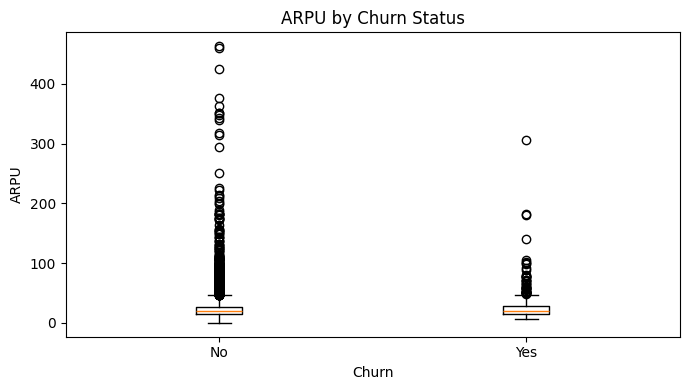

In [ ]:
# ── Cell 21: Numerical feature distributions by churn status ─────────
# Purpose:
# 1. Visualise differences between churned and retained customers
# 2. Compare the distributions of key numerical features
# 3. Identify differences in medians, spread and extreme observations

import matplotlib.pyplot as plt


# Select the most relevant numerical variables from the EDA
churn_comparison_columns = [
    "Active_subscribers",
    "Total_SUBs",
    "TotalRevenue",
    "ARPU"
]


# Use the cleaned data for visualisation
churn_plot_pd = (
    df_clean
    .select(["CHURN"] + churn_comparison_columns)
    .toPandas()
)


# Create one boxplot for each numerical feature
for column in churn_comparison_columns:

    no_churn = churn_plot_pd.loc[
        churn_plot_pd["CHURN"] == "No", column
    ]

    yes_churn = churn_plot_pd.loc[
        churn_plot_pd["CHURN"] == "Yes", column
    ]

    plt.figure(figsize=(7, 4))

    plt.boxplot(
        [no_churn, yes_churn],
        labels=["No", "Yes"]
    )

    plt.title(f"{column} by Churn Status")
    plt.xlabel("Churn")
    plt.ylabel(column)

    plt.tight_layout()
    plt.show()

Boxplots supported the earlier comparisons, showing differences in subscriber and revenue distributions between churned and retained customers. Considerable overlap remained between the groups, indicating that these variables alone were unlikely to separate churn outcomes reliably.

# 5. Feature Engineering and Preprocessing

Following data cleaning and exploratory data analysis, the dataset was prepared for machine learning. This stage considers feature selection and redundancy, the creation of additional informative features, categorical encoding, target-variable preparation and the handling of class imbalance. Preprocessing decisions were informed by the characteristics and relationships identified during exploratory analysis.

In [ ]:
# ── Cell 22: Feature-selection and redundancy audit ──────────────────
# Purpose:
# 1. Define the candidate predictor variables
# 2. Document variables with known redundancy or modelling concerns
# 3. Support transparent feature-selection decisions

candidate_features = [
    "CRM_PID_Value_Segment",
    "EffectiveSegment",
    "Billing_ZIP",
    "Active_subscribers",
    "Not_Active_subscribers",
    "Suspended_subscribers",
    "Total_SUBs",
    "AvgMobileRevenue",
    "AvgFIXRevenue",
    "TotalRevenue",
    "ARPU"
]

target_column = "CHURN"

print("=== Candidate predictor variables ===")
for feature in candidate_features:
    print(feature)

print("\nTarget variable:", target_column)

print("\n=== Feature-selection considerations ===")
print(
    "Total_SUBs: exact mathematical combination of Active, "
    "Not Active and Suspended subscribers."
)
print(
    "AvgMobileRevenue and TotalRevenue: Pearson correlation = 0.994."
)
print(
    "Billing_ZIP: 457 distinct categories; requires consideration "
    "before categorical encoding."
)

=== Candidate predictor variables ===
CRM_PID_Value_Segment
EffectiveSegment
Billing_ZIP
Active_subscribers
Not_Active_subscribers
Suspended_subscribers
Total_SUBs
AvgMobileRevenue
AvgFIXRevenue
TotalRevenue
ARPU

Target variable: CHURN

=== Feature-selection considerations ===
Total_SUBs: exact mathematical combination of Active, Not Active and Suspended subscribers.
AvgMobileRevenue and TotalRevenue: Pearson correlation = 0.994.
Billing_ZIP: 457 distinct categories; requires consideration before categorical encoding.


Feature-selection audit: Preliminary feature selection identified potential redundancy among the numerical predictors. Total_SUBs is mathematically derived from the three subscriber-status variables, while AvgMobileRevenue and TotalRevenue demonstrated an extremely strong correlation (r = 0.994). Billing_ZIP also contains 457 distinct values and therefore requires further investigation before categorical encoding. These features were not removed at this stage; instead, their suitability was assessed before finalising the modelling feature set.

In [ ]:
# ── Cell 23: Billing ZIP frequency and cardinality assessment ─────────
# Purpose:
# 1. Examine the frequency distribution of Billing_ZIP
# 2. Determine how many ZIP categories contain very few observations
# 3. Assess whether raw Billing_ZIP is suitable for categorical encoding

from pyspark.sql import functions as F


# Count customers within each ZIP code
zip_frequency = (
    df_clean
    .groupBy("Billing_ZIP")
    .agg(F.count("*").alias("Customer_Count"))
    .orderBy(F.desc("Customer_Count"))
)


# ── 1. Basic ZIP summary ──────────────────────────────────────────────

total_zip_codes = zip_frequency.count()

single_customer_zips = (
    zip_frequency
    .filter(F.col("Customer_Count") == 1)
    .count()
)

five_or_fewer_zips = (
    zip_frequency
    .filter(F.col("Customer_Count") <= 5)
    .count()
)

ten_or_fewer_zips = (
    zip_frequency
    .filter(F.col("Customer_Count") <= 10)
    .count()
)


print("=== Billing ZIP cardinality assessment ===")
print(f"Distinct ZIP codes           : {total_zip_codes}")
print(f"ZIP codes with 1 customer    : {single_customer_zips}")
print(f"ZIP codes with <= 5 customers: {five_or_fewer_zips}")
print(f"ZIP codes with <=10 customers: {ten_or_fewer_zips}")


# ── 2. Most common ZIP codes ─────────────────────────────────────────

print("\n=== 20 most common Billing ZIP codes ===")

zip_frequency.show(20, truncate=False)


# ── 3. Distribution of ZIP category sizes ────────────────────────────

print("\n=== Distribution of customers per ZIP code ===")

zip_frequency.select("Customer_Count").summary().show()


# ── 4. Coverage of the most common ZIP codes ─────────────────────────

total_customers = df_clean.count()

top_10_customers = (
    zip_frequency
    .limit(10)
    .agg(F.sum("Customer_Count"))
    .first()[0]
)

top_20_customers = (
    zip_frequency
    .limit(20)
    .agg(F.sum("Customer_Count"))
    .first()[0]
)


print(
    f"\nCustomers represented by top 10 ZIP codes: "
    f"{top_10_customers} "
    f"({top_10_customers / total_customers * 100:.2f}%)"
)

print(
    f"Customers represented by top 20 ZIP codes: "
    f"{top_20_customers} "
    f"({top_20_customers / total_customers * 100:.2f}%)"
)

=== Billing ZIP cardinality assessment ===
Distinct ZIP codes           : 457
ZIP codes with 1 customer    : 213
ZIP codes with <= 5 customers: 364
ZIP codes with <=10 customers: 401

=== 20 most common Billing ZIP codes ===
+-----------+--------------+
|Billing_ZIP|Customer_Count|
+-----------+--------------+
|4000       |1606          |
|6000       |1142          |
|4400       |467           |
|4003       |400           |
|6300       |338           |
|4004       |310           |
|4002       |303           |
|4023       |262           |
|6100       |257           |
|4230       |244           |
|6400       |237           |
|6600       |232           |
|4700       |184           |
|4300       |132           |
|4600       |115           |
|6500       |96            |
|4500       |94            |
|6450       |85            |
|4270       |73            |
|4150       |71            |
+-----------+--------------+
only showing top 20 rows

=== Distribution of customers per ZIP code ===
+-----

Assessment of Billing ZIP: Billing_ZIP contained 457 distinct categories and exhibited substantial sparsity. Of these categories, 213 contained only one customer, 364 contained five or fewer customers, and 401 contained ten or fewer customers. The median ZIP category contained only two observations, while the distribution was highly concentrated, with the ten most common ZIP codes representing 63.04% of customers and the twenty most common representing 78.65%. Direct one-hot encoding would therefore introduce a large number of sparse features, many representing very few observations, which could increase dimensionality and encourage overfitting to highly specific geographic patterns. As the dataset documentation does not provide a defensible broader geographic grouping, raw Billing_ZIP will be excluded from the initial modelling feature set.

In [ ]:
# ── Cell 24: Subscriber proportion feature engineering ───────────────
# Purpose:
# 1. Create subscriber-status proportions relative to total subscribers
# 2. Capture customer composition independently of absolute business size
# 3. Assess whether engineered features differ by churn status

from pyspark.sql import functions as F


# Create a feature-engineered DataFrame
df_features = (
    df_clean

    .withColumn(
        "Active_Ratio",
        F.col("Active_subscribers") / F.col("Total_SUBs")
    )

    .withColumn(
        "Inactive_Ratio",
        F.col("Not_Active_subscribers") / F.col("Total_SUBs")
    )

    .withColumn(
        "Suspended_Ratio",
        F.col("Suspended_subscribers") / F.col("Total_SUBs")
    )
)


# ── 1. Inspect engineered features ────────────────────────────────────

print("=== Example engineered subscriber features ===")

df_features.select(
    "Active_subscribers",
    "Not_Active_subscribers",
    "Suspended_subscribers",
    "Total_SUBs",
    "Active_Ratio",
    "Inactive_Ratio",
    "Suspended_Ratio",
    "CHURN"
).show(20, truncate=False)


# ── 2. Verify that proportions sum to 1 ───────────────────────────────

print("\n=== Verify subscriber proportions ===")

df_features.select(
    F.round(
        F.col("Active_Ratio")
        + F.col("Inactive_Ratio")
        + F.col("Suspended_Ratio"),
        6
    ).alias("Ratio_Sum")
).groupBy("Ratio_Sum").count().show()


# ── 3. Compare engineered features by churn status ───────────────────

print("\n=== Average subscriber ratios by churn status ===")

(
    df_features
    .groupBy("CHURN")
    .agg(
        F.count("*").alias("Customers"),

        F.round(F.avg("Active_Ratio"), 4)
        .alias("Avg_Active_Ratio"),

        F.round(F.avg("Inactive_Ratio"), 4)
        .alias("Avg_Inactive_Ratio"),

        F.round(F.avg("Suspended_Ratio"), 4)
        .alias("Avg_Suspended_Ratio")
    )
    .show()
)

=== Example engineered subscriber features ===
+------------------+----------------------+---------------------+----------+-------------------+-------------------+---------------+-----+
|Active_subscribers|Not_Active_subscribers|Suspended_subscribers|Total_SUBs|Active_Ratio       |Inactive_Ratio     |Suspended_Ratio|CHURN|
+------------------+----------------------+---------------------+----------+-------------------+-------------------+---------------+-----+
|2                 |0                     |0                    |2         |1.0                |0.0                |0.0            |No   |
|3                 |0                     |0                    |3         |1.0                |0.0                |0.0            |No   |
|2                 |3                     |0                    |5         |0.4                |0.6                |0.0            |No   |
|1                 |2                     |0                    |3         |0.3333333333333333 |0.6666666666666666 |0.0

Subscriber proportion feature engineering: Three subscriber-status proportions were engineered to represent active, inactive and suspended subscribers relative to each customer's total subscriber base. Validation confirmed that the three proportions summed to 1 for all 8,453 observations. Churned customers exhibited a slightly lower average active subscriber ratio (0.8300) than retained customers (0.8398), alongside a slightly higher inactive subscriber ratio (0.1645 versus 0.1544). Average suspended subscriber ratios were almost identical between the groups. These differences were relatively small and should therefore not be interpreted as strong univariate predictors of churn. As the three engineered ratios are mathematically dependent, all three will not be included simultaneously in the modelling feature set.

In [ ]:
# ── Cell 25: Final modelling feature selection ───────────────────────
# Purpose:
# 1. Apply feature-selection decisions informed by cleaning and EDA
# 2. Retain informative original and engineered predictors
# 3. Remove highly redundant or unsuitable variables

categorical_features = [
    "CRM_PID_Value_Segment",
    "EffectiveSegment"
]

numerical_features = [
    "Active_subscribers",
    "Not_Active_subscribers",
    "Suspended_subscribers",
    "AvgMobileRevenue",
    "AvgFIXRevenue",
    "ARPU",
    "Inactive_Ratio"
]

selected_features = categorical_features + numerical_features

target_column = "CHURN"


# Create modelling DataFrame containing selected predictors and target
df_model = df_features.select(
    selected_features + [target_column]
)


print("=== Final categorical predictors ===")
for feature in categorical_features:
    print(feature)

print("\n=== Final numerical predictors ===")
for feature in numerical_features:
    print(feature)

print("\n=== Excluded predictors ===")
print("Billing_ZIP       -> high cardinality and sparse categories")
print("Total_SUBs        -> exact combination of subscriber-status variables")
print("TotalRevenue      -> near-duplicate of AvgMobileRevenue (r = 0.994)")
print("Active_Ratio      -> excluded to avoid redundant ratio representation")
print("Suspended_Ratio   -> limited churn separation and ratio redundancy")


print("\n=== Final modelling dataset ===")
print("Rows:", df_model.count())
print("Predictors:", len(selected_features))
print("Target:", target_column)

df_model.printSchema()

=== Final categorical predictors ===
CRM_PID_Value_Segment
EffectiveSegment

=== Final numerical predictors ===
Active_subscribers
Not_Active_subscribers
Suspended_subscribers
AvgMobileRevenue
AvgFIXRevenue
ARPU
Inactive_Ratio

=== Excluded predictors ===
Billing_ZIP       -> high cardinality and sparse categories
Total_SUBs        -> exact combination of subscriber-status variables
TotalRevenue      -> near-duplicate of AvgMobileRevenue (r = 0.994)
Active_Ratio      -> excluded to avoid redundant ratio representation
Suspended_Ratio   -> limited churn separation and ratio redundancy

=== Final modelling dataset ===
Rows: 8453
Predictors: 9
Target: CHURN
root
 |-- CRM_PID_Value_Segment: string (nullable = false)
 |-- EffectiveSegment: string (nullable = true)
 |-- Active_subscribers: integer (nullable = true)
 |-- Not_Active_subscribers: integer (nullable = false)
 |-- Suspended_subscribers: integer (nullable = false)
 |-- AvgMobileRevenue: double (nullable = true)
 |-- AvgFIXRevenue: 

Final feature selection: Following data cleaning, exploratory analysis and feature engineering, nine predictor variables were selected for subsequent modelling: two categorical and seven numerical features. Billing_ZIP was excluded due to its high cardinality and sparse category distribution, while Total_SUBs was removed because it is mathematically derived from the three subscriber-status variables. TotalRevenue was excluded because of its near-perfect correlation with AvgMobileRevenue (r = 0.994). Of the engineered subscriber proportions, Inactive_Ratio was retained to represent inactivity relative to customer size, while the remaining ratios were excluded to avoid unnecessary mathematical redundancy. The resulting modelling dataset contains 8,453 observations, nine predictors and the CHURN target variable.

In [ ]:
# ── Cell 26: Binary target label creation ─────────────────────────────
# Purpose:
# 1. Convert the categorical CHURN target into a numerical label
# 2. Define churn as the positive class (1)
# 3. Verify that the transformation preserves the original class counts

from pyspark.sql import functions as F


# Create binary target label
df_model = df_model.withColumn(
    "label",
    F.when(F.col("CHURN") == "Yes", 1.0)
     .when(F.col("CHURN") == "No", 0.0)
)


# ── 1. Verify target conversion ───────────────────────────────────────

print("=== CHURN to label mapping ===")

(
    df_model
    .groupBy("CHURN", "label")
    .count()
    .orderBy("label")
    .show()
)


# ── 2. Verify label distribution ─────────────────────────────────────

print("\n=== Binary label distribution ===")

label_distribution = (
    df_model
    .groupBy("label")
    .count()
    .withColumn(
        "Percentage",
        F.round(
            F.col("count") / df_model.count() * 100,
            2
        )
    )
    .orderBy("label")
)

label_distribution.show()


# ── 3. Check for invalid or missing labels ────────────────────────────

invalid_labels = (
    df_model
    .filter(
        F.col("label").isNull()
        | (~F.col("label").isin(0.0, 1.0))
    )
    .count()
)

print(f"\nInvalid or missing labels: {invalid_labels}")

=== CHURN to label mapping ===
+-----+-----+-----+
|CHURN|label|count|
+-----+-----+-----+
|   No|  0.0| 7904|
|  Yes|  1.0|  549|
+-----+-----+-----+


=== Binary label distribution ===
+-----+-----+----------+
|label|count|Percentage|
+-----+-----+----------+
|  0.0| 7904|     93.51|
|  1.0|  549|      6.49|
+-----+-----+----------+


Invalid or missing labels: 0


Target-variable encoding: The categorical CHURN target was converted into a binary numerical label suitable for machine-learning classification. Non-churned customers were encoded as 0, while churned customers were encoded as 1, establishing churn as the positive class. Validation confirmed that the transformation preserved the original target distribution, with 7,904 non-churned customers (93.51%) and 549 churned customers (6.49%), and no invalid or missing labels were produced. The resulting distribution demonstrates substantial class imbalance, which will be considered during model training and evaluation.

In [ ]:
# ── Cell 27: Deterministic stratified 80:20 train/test split ─────────
# Purpose:
# 1. Replace the probabilistic randomSplit approach
# 2. Allocate approximately 80% of EACH target class to training
# 3. Preserve the original churn distribution in both datasets
# 4. Use a fixed seed to support reproducibility

from pyspark.sql import functions as F
from pyspark.sql.window import Window
import math


SEED = 42
TRAIN_PROPORTION = 0.80


# ── 1. Obtain class counts ────────────────────────────────────────────

class_count_rows = (
    df_model
    .groupBy("label")
    .count()
    .collect()
)

class_counts = {
    row["label"]: row["count"]
    for row in class_count_rows
}


# Calculate exact training allocation for each class
train_counts = {
    label: math.floor(count * TRAIN_PROPORTION)
    for label, count in class_counts.items()
}


print("=== Planned stratified allocation ===")

for label in sorted(class_counts):

    total = class_counts[label]
    train_n = train_counts[label]
    test_n = total - train_n

    print(
        f"Label {label}: "
        f"Total={total}, "
        f"Train={train_n}, "
        f"Test={test_n}"
    )


# ── 2. Randomly order observations WITHIN each class ─────────────────

class_window = (
    Window
    .partitionBy("label")
    .orderBy(F.rand(SEED))
)

df_ranked = (
    df_model
    .withColumn(
        "_stratified_row_number",
        F.row_number().over(class_window)
    )
)


# ── 3. Allocate exact training observations by class ─────────────────

train_df = (
    df_ranked
    .filter(
        (
            (F.col("label") == 0.0) &
            (F.col("_stratified_row_number") <= train_counts[0.0])
        )
        |
        (
            (F.col("label") == 1.0) &
            (F.col("_stratified_row_number") <= train_counts[1.0])
        )
    )
    .drop("_stratified_row_number")
    .cache()
)


# ── 4. Remaining observations form the held-out test set ─────────────

test_df = (
    df_ranked
    .filter(
        (
            (F.col("label") == 0.0) &
            (F.col("_stratified_row_number") > train_counts[0.0])
        )
        |
        (
            (F.col("label") == 1.0) &
            (F.col("_stratified_row_number") > train_counts[1.0])
        )
    )
    .drop("_stratified_row_number")
    .cache()
)


# ── 5. Verify dataset sizes ───────────────────────────────────────────

train_count = train_df.count()
test_count = test_df.count()


print("\n=== Revised stratified train/test split ===")

print(f"Training observations: {train_count}")
print(f"Test observations    : {test_count}")
print(f"Total observations   : {train_count + test_count}")


# ── 6. Verify class distributions ─────────────────────────────────────

def display_distribution(dataframe, name):

    total = dataframe.count()

    print(f"\n=== {name} class distribution ===")

    (
        dataframe
        .groupBy("label")
        .count()
        .withColumn(
            "Percentage",
            F.round(
                F.col("count") / total * 100,
                2
            )
        )
        .orderBy("label")
        .show()
    )


display_distribution(train_df, "Training set")
display_distribution(test_df, "Test set")

=== Planned stratified allocation ===
Label 0.0: Total=7904, Train=6323, Test=1581
Label 1.0: Total=549, Train=439, Test=110

=== Revised stratified train/test split ===
Training observations: 6762
Test observations    : 1691
Total observations   : 8453

=== Training set class distribution ===
+-----+-----+----------+
|label|count|Percentage|
+-----+-----+----------+
|  0.0| 6323|     93.51|
|  1.0|  439|      6.49|
+-----+-----+----------+


=== Test set class distribution ===
+-----+-----+----------+
|label|count|Percentage|
+-----+-----+----------+
|  0.0| 1581|     93.49|
|  1.0|  110|      6.51|
+-----+-----+----------+



Stratified train/test split: A deterministic stratified 80:20 train/test split was implemented using a fixed random seed of 42 to preserve the original target-class distribution while supporting reproducibility. Of the 8,453 observations, 6,762 were allocated to training and 1,691 to the held-out test set. The training set contained 6.49% churned customers, while the test set contained 6.51%, closely reflecting the original dataset churn rate of 6.49%. This resulted in 439 churn observations for model development and 110 churn observations for final evaluation. The held-out test set will remain untouched during model fitting, preprocessing optimisation and hyperparameter selection and will be used only for final model evaluation.

In [ ]:
# ── Cell 28: Train/test class-distribution audit ──────────────────────
# Purpose:
# 1. Verify representation of churn and non-churn classes
# 2. Compare class proportions between training and test sets
# 3. Confirm that sufficient minority-class observations remain for evaluation

from pyspark.sql import functions as F


def show_class_distribution(dataframe, dataset_name):

    total = dataframe.count()

    distribution = (
        dataframe
        .groupBy("label")
        .count()
        .withColumn(
            "Percentage",
            F.round(
                (F.col("count") / total) * 100,
                2
            )
        )
        .orderBy("label")
    )

    print(f"\n=== {dataset_name} class distribution ===")
    distribution.show()


# Training distribution
show_class_distribution(
    train_df,
    "Training set"
)


# Test distribution
show_class_distribution(
    test_df,
    "Test set"
)


=== Training set class distribution ===
+-----+-----+----------+
|label|count|Percentage|
+-----+-----+----------+
|  0.0| 6323|     93.51|
|  1.0|  439|      6.49|
+-----+-----+----------+


=== Test set class distribution ===
+-----+-----+----------+
|label|count|Percentage|
+-----+-----+----------+
|  0.0| 1581|     93.49|
|  1.0|  110|      6.51|
+-----+-----+----------+



Class-distribution verification: The training set contained 6,323 non-churned customers (93.51%) and 439 churned customers (6.49%), while the test set contained 1,581 non-churned customers (93.49%) and 110 churned customers (6.51%). Although the proportions differ slightly from the original dataset churn rate of 6.49%, both subsets retain representation of the minority churn class. The training set therefore provides 465 churn observations for model development, while the held-out test set provides 84 churn observations for final evaluation. The test set will retain its naturally imbalanced distribution and will not be resampled or balanced.

In [ ]:
# ── Cell 29: Preprocessing architecture and feature-name plan ─────────
# Purpose:
# 1. Define which variables require categorical encoding
# 2. Define which variables are already numerical
# 3. Estimate the expected dimensionality after one-hot encoding
# 4. Preserve original feature identities for later SHAP interpretation
# 5. Separate scaling decisions from categorical encoding

from pyspark.sql import functions as F


# ── 1. Final feature groups ───────────────────────────────────────────

categorical_features = [
    "CRM_PID_Value_Segment",
    "EffectiveSegment"
]

numerical_features = [
    "Active_subscribers",
    "Not_Active_subscribers",
    "Suspended_subscribers",
    "AvgMobileRevenue",
    "AvgFIXRevenue",
    "ARPU",
    "Inactive_Ratio"
]


print("=== Preprocessing architecture ===")

print("\nCategorical features requiring encoding:")
for feature in categorical_features:
    print(f" - {feature}")

print("\nNumerical features retained in original form:")
for feature in numerical_features:
    print(f" - {feature}")


# ── 2. Count categories using TRAINING DATA ONLY ──────────────────────

print("\n=== Training-set categorical cardinality ===")

category_counts = {}

for feature in categorical_features:

    n_categories = (
        train_df
        .select(feature)
        .distinct()
        .count()
    )

    category_counts[feature] = n_categories

    print(f"{feature}: {n_categories} observed categories")


# ── 3. Estimate encoded feature dimensionality ────────────────────────
# OneHotEncoder normally drops one category from each variable by default.

estimated_ohe_features = sum(
    max(count - 1, 1)
    for count in category_counts.values()
)

estimated_total_features = (
    estimated_ohe_features
    + len(numerical_features)
)


print("\n=== Estimated modelling dimensionality ===")
print(
    f"Estimated one-hot encoded features: {estimated_ohe_features}"
)
print(
    f"Original numerical features       : {len(numerical_features)}"
)
print(
    f"Estimated total model features    : {estimated_total_features}"
)


# ── 4. Define readable feature-name structure ─────────────────────────

feature_name_groups = {
    "CRM_PID_Value_Segment": "CRM customer value segment",
    "EffectiveSegment": "Business customer segment",
    "Active_subscribers": "Active subscribers",
    "Not_Active_subscribers": "Inactive subscribers",
    "Suspended_subscribers": "Suspended subscribers",
    "AvgMobileRevenue": "Average mobile revenue",
    "AvgFIXRevenue": "Average fixed revenue",
    "ARPU": "Average revenue per user",
    "Inactive_Ratio": "Inactive subscriber ratio"
}


print("\n=== Feature-name mapping retained for interpretation ===")

for feature, readable_name in feature_name_groups.items():
    print(f"{feature} -> {readable_name}")


print(
    "\nNo encoding or scaling has been fitted in this cell."
)

=== Preprocessing architecture ===

Categorical features requiring encoding:
 - CRM_PID_Value_Segment
 - EffectiveSegment

Numerical features retained in original form:
 - Active_subscribers
 - Not_Active_subscribers
 - Suspended_subscribers
 - AvgMobileRevenue
 - AvgFIXRevenue
 - ARPU
 - Inactive_Ratio

=== Training-set categorical cardinality ===
CRM_PID_Value_Segment: 9 observed categories
EffectiveSegment: 6 observed categories

=== Estimated modelling dimensionality ===
Estimated one-hot encoded features: 13
Original numerical features       : 7
Estimated total model features    : 20

=== Feature-name mapping retained for interpretation ===
CRM_PID_Value_Segment -> CRM customer value segment
EffectiveSegment -> Business customer segment
Active_subscribers -> Active subscribers
Not_Active_subscribers -> Inactive subscribers
Suspended_subscribers -> Suspended subscribers
AvgMobileRevenue -> Average mobile revenue
AvgFIXRevenue -> Average fixed revenue
ARPU -> Average revenue per use

Preprocessing design: The final feature set contains two low-cardinality categorical predictors and seven numerical predictors. Categorical cardinality was assessed using the training data before encoding to estimate the dimensionality introduced through one-hot encoding. This confirmed that categorical transformation would produce a relatively small feature space, avoiding the high-dimensional sparse representation that would have resulted from including Billing_ZIP. Original feature identities and human-readable names were retained explicitly to support subsequent model interpretation and SHAP analysis. Scaling will be applied selectively to algorithms that benefit from standardised numerical inputs rather than universally across all models. The estimated dimensionality of approximately 20 model inputs confirms that the preprocessing design remains computationally manageable for cross-validation and subsequent SHAP analysis.

In [ ]:
# ── Cell 30: Fit categorical preprocessing on training data ──────────
# Purpose:
# 1. Index categorical variables using training data only
# 2. One-hot encode the indexed categorical variables
# 3. Apply the fitted transformations to both training and test sets
# 4. Preserve category information for later feature-name reconstruction

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder


# ── 1. Define StringIndexer stages ───────────────────────────────────

indexers = [
    StringIndexer(
        inputCol=feature,
        outputCol=f"{feature}_Index",
        handleInvalid="keep"
    )
    for feature in categorical_features
]


# ── 2. Define OneHotEncoder stage ────────────────────────────────────

encoder = OneHotEncoder(
    inputCols=[
        f"{feature}_Index"
        for feature in categorical_features
    ],
    outputCols=[
        f"{feature}_OHE"
        for feature in categorical_features
    ],
    handleInvalid="keep",
    dropLast=True
)


# ── 3. Build categorical preprocessing pipeline ──────────────────────

categorical_pipeline = Pipeline(
    stages=indexers + [encoder]
)


# ── 4. Fit pipeline on TRAINING DATA ONLY ────────────────────────────

categorical_model = categorical_pipeline.fit(train_df)


# ── 5. Transform training and test data ──────────────────────────────

train_encoded = categorical_model.transform(train_df)
test_encoded = categorical_model.transform(test_df)


# ── 6. Verify generated columns ──────────────────────────────────────

print("=== Encoded training columns ===")

for feature in categorical_features:
    print(
        f"{feature} -> "
        f"{feature}_Index -> "
        f"{feature}_OHE"
    )


print("\nTraining rows:", train_encoded.count())
print("Test rows    :", test_encoded.count())


print("\n=== Example encoded output ===")

train_encoded.select(
    "CRM_PID_Value_Segment",
    "CRM_PID_Value_Segment_Index",
    "CRM_PID_Value_Segment_OHE",
    "EffectiveSegment",
    "EffectiveSegment_Index",
    "EffectiveSegment_OHE",
    "label"
).show(10, truncate=False)

=== Encoded training columns ===
CRM_PID_Value_Segment -> CRM_PID_Value_Segment_Index -> CRM_PID_Value_Segment_OHE
EffectiveSegment -> EffectiveSegment_Index -> EffectiveSegment_OHE

Training rows: 6762
Test rows    : 1691

=== Example encoded output ===
+---------------------+---------------------------+-------------------------+----------------+----------------------+--------------------+-----+
|CRM_PID_Value_Segment|CRM_PID_Value_Segment_Index|CRM_PID_Value_Segment_OHE|EffectiveSegment|EffectiveSegment_Index|EffectiveSegment_OHE|label|
+---------------------+---------------------------+-------------------------+----------------+----------------------+--------------------+-----+
|Bronze               |0.0                        |(10,[0],[1.0])           |SOHO            |0.0                   |(7,[0],[1.0])       |0.0  |
|SME                  |4.0                        |(10,[4],[1.0])           |SME             |2.0                   |(7,[2],[1.0])       |0.0  |
|SME                

Categorical encoding: The two categorical predictors were indexed and one-hot encoded using a preprocessing pipeline fitted exclusively on the training dataset. The fitted pipeline was subsequently applied to both the training and held-out test datasets, preserving all 6,762 training observations and 1,691 test observations. handleInvalid="keep" was used to allow previously unseen categories in the test data to be represented without fitting the preprocessing transformations on the test set. This resulted in encoded vector sizes of 10 for CRM_PID_Value_Segment and 7 for EffectiveSegment. The resulting dimensionality remains small and computationally manageable.

In [ ]:
# ── Cell 31: Recover encoded feature names ────────────────────────────
# Purpose:
# 1. Extract readable names for one-hot encoded features
# 2. Preserve the exact order of encoded variables
# 3. Build a feature-name list for later modelling and SHAP analysis

encoded_feature_names = []


for feature in categorical_features:

    ohe_column = f"{feature}_OHE"

    print(f"\n=== Feature names for {ohe_column} ===")

    # Metadata generated by Spark during one-hot encoding
    metadata = train_encoded.schema[ohe_column].metadata

    attributes = (
        metadata
        .get("ml_attr", {})
        .get("attrs", {})
    )

    feature_attributes = []

    # Extract all available attribute names and indices
    for attribute_type in attributes:

        for attribute in attributes[attribute_type]:

            feature_attributes.append(
                (
                    attribute["idx"],
                    attribute.get(
                        "name",
                        f"{ohe_column}_{attribute['idx']}"
                    )
                )
            )

    # Sort into the exact vector order
    feature_attributes = sorted(
        feature_attributes,
        key=lambda x: x[0]
    )

    # Display and store names
    for index, name in feature_attributes:

        readable_name = f"{feature}_{name}"

        print(f"{index}: {readable_name}")

        encoded_feature_names.append(readable_name)


# ── Add original numerical feature names ─────────────────────────────

final_feature_names = (
    encoded_feature_names
    + numerical_features
)


print("\n=== Final readable model feature names ===")

for index, feature in enumerate(final_feature_names):
    print(f"{index}: {feature}")


print(
    f"\nTotal readable features identified: "
    f"{len(final_feature_names)}"
)


=== Feature names for CRM_PID_Value_Segment_OHE ===
0: CRM_PID_Value_Segment_Bronze
1: CRM_PID_Value_Segment_Silver
2: CRM_PID_Value_Segment_Gold
3: CRM_PID_Value_Segment_Platinum
4: CRM_PID_Value_Segment_SME
5: CRM_PID_Value_Segment_Iron
6: CRM_PID_Value_Segment_SE
7: CRM_PID_Value_Segment_Lead
8: CRM_PID_Value_Segment_Unknown
9: CRM_PID_Value_Segment___unknown

=== Feature names for EffectiveSegment_OHE ===
0: EffectiveSegment_SOHO
1: EffectiveSegment_VSE
2: EffectiveSegment_SME
3: EffectiveSegment_SE
4: EffectiveSegment_Other
5: EffectiveSegment_LE
6: EffectiveSegment___unknown

=== Final readable model feature names ===
0: CRM_PID_Value_Segment_Bronze
1: CRM_PID_Value_Segment_Silver
2: CRM_PID_Value_Segment_Gold
3: CRM_PID_Value_Segment_Platinum
4: CRM_PID_Value_Segment_SME
5: CRM_PID_Value_Segment_Iron
6: CRM_PID_Value_Segment_SE
7: CRM_PID_Value_Segment_Lead
8: CRM_PID_Value_Segment_Unknown
9: CRM_PID_Value_Segment___unknown
10: EffectiveSegment_SOHO
11: EffectiveSegment_VSE
12:

Feature-name preservation: Metadata from the fitted one-hot encoding pipeline was used to recover the exact names and ordering of the transformed categorical features. This produced 17 encoded categorical inputs and seven numerical inputs, resulting in a final feature space of 24 variables. Reserved __unknown categories were retained to accommodate unseen test-set categories without refitting the preprocessing pipeline. Maintaining this explicit feature-name mapping ensures that subsequent model coefficients, feature importance measures and SHAP explanations can be translated back into meaningful business variables rather than anonymous vector positions.

In [ ]:
# ── Cell 32: Assemble unscaled model feature vector ───────────────────
# Purpose:
# 1. Combine encoded categorical and numerical predictors
# 2. Create an unscaled feature vector for tree-based models
# 3. Preserve the 24-feature order established in Cell 31

from pyspark.ml.feature import VectorAssembler


# Encoded categorical feature columns
encoded_categorical_columns = [
    "CRM_PID_Value_Segment_OHE",
    "EffectiveSegment_OHE"
]


# Assemble encoded categoricals + original numerical predictors
tree_assembler = VectorAssembler(
    inputCols=encoded_categorical_columns + numerical_features,
    outputCol="features_unscaled"
)


# Apply to training and test datasets
train_prepared = tree_assembler.transform(train_encoded)
test_prepared = tree_assembler.transform(test_encoded)


# ── Verification ──────────────────────────────────────────────────────

print("=== Unscaled feature-vector preparation ===")

print("Training rows:", train_prepared.count())
print("Test rows    :", test_prepared.count())

print("\n=== Example feature vector ===")

train_prepared.select(
    "features_unscaled",
    "label"
).show(5, truncate=False)


print("\nExpected readable features:", len(final_feature_names))

=== Unscaled feature-vector preparation ===
Training rows: 6762
Test rows    : 1691

=== Example feature vector ===
+--------------------------------------------------------------+-----+
|features_unscaled                                             |label|
+--------------------------------------------------------------+-----+
|(24,[0,10,17,18,20,22,23],[1.0,1.0,4.0,1.0,52.17,13.04,0.2])  |0.0  |
|(24,[4,12,17,20,22],[1.0,1.0,34.0,363.0,10.68])               |0.0  |
|(24,[4,12,17,20,22],[1.0,1.0,19.0,438.83,23.1])               |0.0  |
|(24,[0,10,17,20,22],[1.0,1.0,5.0,203.33,40.67])               |0.0  |
|(24,[0,10,17,18,20,22,23],[1.0,1.0,3.0,5.0,126.5,42.17,0.625])|0.0  |
+--------------------------------------------------------------+-----+
only showing top 5 rows

Expected readable features: 24


Unscaled feature-vector preparation: The one-hot encoded categorical variables and seven numerical predictors were assembled into a 24-dimensional features_unscaled vector. The transformation preserved all 6,762 training observations and 1,691 test observations. This unscaled representation will be used for tree-based algorithms, which do not require numerical standardisation in the same way as linear models. The feature ordering remains consistent with the readable feature-name mapping established previously, supporting later feature importance and SHAP interpretation.

In [ ]:
# ── Cell 33: Scale numerical features for Logistic Regression ────────
# Purpose:
# 1. Assemble the seven numerical predictors
# 2. Fit StandardScaler on training data only
# 3. Apply the fitted scaler to both training and test sets
# 4. Preserve categorical OHE features separately

from pyspark.ml.feature import VectorAssembler, StandardScaler


# ── 1. Assemble numerical predictors ─────────────────────────────────

numerical_assembler = VectorAssembler(
    inputCols=numerical_features,
    outputCol="numerical_features"
)

train_with_numeric = numerical_assembler.transform(train_encoded)
test_with_numeric = numerical_assembler.transform(test_encoded)


# ── 2. Define StandardScaler ─────────────────────────────────────────

scaler = StandardScaler(
    inputCol="numerical_features",
    outputCol="numerical_features_scaled",
    withStd=True,
    withMean=True
)


# ── 3. Fit scaler on TRAINING DATA ONLY ──────────────────────────────

scaler_model = scaler.fit(train_with_numeric)


# ── 4. Transform training and test data ──────────────────────────────

train_scaled = scaler_model.transform(train_with_numeric)
test_scaled = scaler_model.transform(test_with_numeric)


# ── 5. Verification ──────────────────────────────────────────────────

print("=== Numerical scaling for Logistic Regression ===")

print("Training rows:", train_scaled.count())
print("Test rows    :", test_scaled.count())

print("\n=== Example numerical vectors ===")

train_scaled.select(
    "numerical_features",
    "numerical_features_scaled",
    "label"
).show(5, truncate=False)

=== Numerical scaling for Logistic Regression ===
Training rows: 6762
Test rows    : 1691

=== Example numerical vectors ===
+-----------------------------------+-----------------------------------------------------------------------------------------------------------------------------------------------+-----+
|numerical_features                 |numerical_features_scaled                                                                                                                      |label|
+-----------------------------------+-----------------------------------------------------------------------------------------------------------------------------------------------+-----+
|[4.0,1.0,0.0,52.17,0.0,13.04,0.2]  |[-0.5680624114686532,-0.1629656027055619,-0.12916136610970622,-0.9328290243995536,-0.07252917128735784,-0.5086448940480219,0.21338701170016114]|0.0  |
|(7,[0,3,5],[34.0,363.0,10.68])     |[4.000126789773342,-0.3132825315686111,-0.12916136610970622,2.1244319971842325,-0.0725

Numerical scaling for Logistic Regression: The seven numerical predictors were assembled into a separate numerical feature vector and standardised using StandardScaler. The scaler was fitted exclusively on the training data and subsequently applied to both the training and test sets to avoid information leakage. Only the numerical predictors were scaled, while the one-hot encoded categorical variables remained unchanged. This model-specific preprocessing strategy supports Logistic Regression without unnecessarily transforming the inputs used by tree-based algorithms.

In [ ]:
# ── Cell 34: Assemble scaled Logistic Regression feature vector ──────
# Purpose:
# 1. Combine OHE categorical features with scaled numerical features
# 2. Create a dedicated feature vector for Logistic Regression
# 3. Preserve separate scaled and unscaled modelling pathways

from pyspark.ml.feature import VectorAssembler


logistic_assembler = VectorAssembler(
    inputCols=[
        "CRM_PID_Value_Segment_OHE",
        "EffectiveSegment_OHE",
        "numerical_features_scaled"
    ],
    outputCol="features_scaled"
)


# Apply to training and test data
train_lr = logistic_assembler.transform(train_scaled)
test_lr = logistic_assembler.transform(test_scaled)


# ── Verification ──────────────────────────────────────────────────────

print("=== Scaled Logistic Regression feature vector ===")

print("Training rows:", train_lr.count())
print("Test rows    :", test_lr.count())

print("\n=== Example scaled feature vector ===")

train_lr.select(
    "features_scaled",
    "label"
).show(5, truncate=False)

=== Scaled Logistic Regression feature vector ===
Training rows: 6762
Test rows    : 1691

=== Example scaled feature vector ===
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|features_scaled                                                                                                                                                                         |label|
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|(24,[0,10,17,18,19,20,21,22,23],[1.0,1.0,-0.5680624114686532,-0.1629656027055619,-0.12916136610970622,-0.9328290243995536,-0.07252917128735784,-0.5086448940480219,0.21338701170016114])|0.0  |
|(24,[4,12,17,18,19,20,21,22,23],[1.0,1.0,4.000126789773342,-0.3132825315686111,-0.1291613661097062

Logistic Regression feature-vector preparation: The one-hot encoded categorical predictors were combined with the seven standardised numerical predictors to create a dedicated 24-dimensional features_scaled vector for Logistic Regression. All categorical variables remained represented through their original one-hot encoded values, while only the numerical predictors were standardised. The transformation preserved all 6,762 training observations and 1,691 test observations. Maintaining a separate scaled feature representation allows Logistic Regression to benefit from numerical standardisation while preserving the unscaled feature vector for tree-based models, thereby avoiding unnecessary preprocessing and supporting subsequent model interpretation.

In [ ]:
# ── Cell 35: Class imbalance strategy assessment ─────────────────────
# Purpose:
# 1. Quantify class imbalance in the training dataset
# 2. Calculate balanced class weights
# 3. Assess the implications of alternative sampling strategies
# 4. Inform the choice of imbalance treatment before model training

from pyspark.sql import functions as F


# ── 1. Obtain training class counts ──────────────────────────────────

class_counts = {
    row["label"]: row["count"]
    for row in train_df.groupBy("label").count().collect()
}

n_non_churn = class_counts[0.0]
n_churn = class_counts[1.0]
n_total = n_non_churn + n_churn


# ── 2. Calculate imbalance ratio ─────────────────────────────────────

imbalance_ratio = n_non_churn / n_churn


print("=== Training-set class imbalance ===")

print(f"Non-churn observations : {n_non_churn}")
print(f"Churn observations     : {n_churn}")
print(f"Total observations     : {n_total}")

print(
    f"Majority : minority ratio = "
    f"{imbalance_ratio:.2f} : 1"
)


# ── 3. Calculate balanced class weights ──────────────────────────────
# Formula:
# weight(class) = total observations /
#                 (number of classes × observations in that class)

n_classes = 2

non_churn_weight = (
    n_total / (n_classes * n_non_churn)
)

churn_weight = (
    n_total / (n_classes * n_churn)
)


print("\n=== Balanced class weights ===")

print(
    f"Non-churn weight (label 0): "
    f"{non_churn_weight:.4f}"
)

print(
    f"Churn weight (label 1)    : "
    f"{churn_weight:.4f}"
)


# ── 4. Assess random undersampling ───────────────────────────────────

undersampled_total = n_churn * 2

majority_records_removed = (
    n_non_churn - n_churn
)

percentage_training_removed = (
    majority_records_removed / n_total
) * 100


print("\n=== Random undersampling implications ===")

print(
    f"Balanced training size       : "
    f"{undersampled_total}"
)

print(
    f"Majority observations removed: "
    f"{majority_records_removed}"
)

print(
    f"Training data removed        : "
    f"{percentage_training_removed:.2f}%"
)


# ── 5. Assess random oversampling / SMOTE ────────────────────────────

minority_records_required = (
    n_non_churn - n_churn
)

balanced_oversampled_total = (
    n_non_churn * 2
)


print("\n=== Oversampling implications ===")

print(
    f"Additional minority observations required: "
    f"{minority_records_required}"
)

print(
    f"Balanced training size                  : "
    f"{balanced_oversampled_total}"
)

print(
    f"Minority-class expansion factor         : "
    f"{n_non_churn / n_churn:.2f}x"
)


# ── 6. Summary ───────────────────────────────────────────────────────

print("\n=== Strategy assessment summary ===")

print(
    "No treatment    -> preserves all original observations "
    "but retains severe imbalance."
)

print(
    "Undersampling   -> balances classes by discarding "
    "majority-class observations."
)

print(
    "Oversampling    -> balances classes by increasing "
    "minority representation."
)

print(
    "SMOTE           -> would generate synthetic minority "
    "observations rather than simple duplicates."
)

print(
    "Class weighting -> preserves all original observations "
    "without generating synthetic customers."
)

=== Training-set class imbalance ===
Non-churn observations : 6323
Churn observations     : 439
Total observations     : 6762
Majority : minority ratio = 14.40 : 1

=== Balanced class weights ===
Non-churn weight (label 0): 0.5347
Churn weight (label 1)    : 7.7016

=== Random undersampling implications ===
Balanced training size       : 878
Majority observations removed: 5884
Training data removed        : 87.02%

=== Oversampling implications ===
Additional minority observations required: 5884
Balanced training size                  : 12646
Minority-class expansion factor         : 14.40x

=== Strategy assessment summary ===
No treatment    -> preserves all original observations but retains severe imbalance.
Undersampling   -> balances classes by discarding majority-class observations.
Oversampling    -> balances classes by increasing minority representation.
SMOTE           -> would generate synthetic minority observations rather than simple duplicates.
Class weighting -> preserves 

Class-imbalance strategy assessment: Following the stratified train/test split, the training dataset contained 6,323 non-churned customers and 439 churned customers, corresponding to a majority-to-minority ratio of 14.40:1. Alternative imbalance treatments were assessed before model development. Random undersampling to full class parity would reduce the training dataset to only 878 observations and discard 5,884 majority-class records, equivalent to 87.02% of the available training data. Conversely, full random oversampling or synthetic oversampling would require an additional 5,884 minority-class observations, representing a 14.40-fold expansion of the churn class. Given the relatively small number of genuine churn observations and the objective of retaining interpretable model inputs, class weighting was selected as the primary imbalance-aware strategy. Balanced weights of approximately 0.5347 for non-churn and 7.7016 for churn were calculated while preserving all original training observations. Untreated baseline models will also be evaluated to determine empirically whether imbalance treatment improves minority-class prediction. The held-out test set will remain unchanged and naturally imbalanced.

In [ ]:
# ── Cell 36: Create class-weight column ───────────────────────────────
# Purpose:
# 1. Apply the balanced class weights calculated in Cell 35
# 2. Preserve every original training observation
# 3. Prepare weighted datasets for imbalance-aware model training
# 4. Avoid manually hard-coding class-weight values

from pyspark.sql import functions as F


# ── 1. Use exact weights calculated in Cell 35 ───────────────────────

NON_CHURN_WEIGHT = non_churn_weight
CHURN_WEIGHT = churn_weight


# ── 2. Add weights to unscaled tree-model training data ──────────────

train_tree_weighted = (
    train_prepared
    .withColumn(
        "classWeight",
        F.when(
            F.col("label") == 1.0,
            F.lit(CHURN_WEIGHT)
        ).otherwise(
            F.lit(NON_CHURN_WEIGHT)
        )
    )
)


# ── 3. Add weights to scaled Logistic Regression training data ───────

train_lr_weighted = (
    train_lr
    .withColumn(
        "classWeight",
        F.when(
            F.col("label") == 1.0,
            F.lit(CHURN_WEIGHT)
        ).otherwise(
            F.lit(NON_CHURN_WEIGHT)
        )
    )
)


# ── 4. Verify weight assignment ──────────────────────────────────────

print("=== Class-weight verification ===")

(
    train_tree_weighted
    .groupBy("label", "classWeight")
    .count()
    .orderBy("label")
    .show(truncate=False)
)


print(
    "Tree-model weighted training rows:",
    train_tree_weighted.count()
)

print(
    "Logistic Regression weighted training rows:",
    train_lr_weighted.count()
)


print("\n=== Applied class weights ===")

print(
    f"Non-churn weight: {NON_CHURN_WEIGHT:.4f}"
)

print(
    f"Churn weight    : {CHURN_WEIGHT:.4f}"
)

=== Class-weight verification ===
+-----+------------------+-----+
|label|classWeight       |count|
+-----+------------------+-----+
|0.0  |0.5347145342400759|6323 |
|1.0  |7.7015945330296125|439  |
+-----+------------------+-----+

Tree-model weighted training rows: 6762
Logistic Regression weighted training rows: 6762

=== Applied class weights ===
Non-churn weight: 0.5347
Churn weight    : 7.7016


Class-weight implementation: Balanced class weights were assigned to the training observations according to their target class, giving greater influence to the minority churn class while retaining every genuine training observation. The weight column was added separately to the unscaled tree-model and scaled Logistic Regression training datasets. No class weights were applied to the held-out test data, as weighting is a model-training intervention and the test set should preserve the naturally occurring class distribution for unbiased evaluation. Verification confirmed that all training observations were retained and assigned the appropriate class-specific weight.

In [ ]:
# ── Cell 37: Save and Verify Prepared Modelling Artefacts ────

import os
import json
import shutil


# ── 1. Define output paths ───────────────────────────────────────

TREE_TRAIN_PATH = os.path.join(OUTPUTS, "train_tree_features")
TREE_TEST_PATH = os.path.join(OUTPUTS, "test_tree_features")

LR_TRAIN_PATH = os.path.join(OUTPUTS, "train_lr_features")
LR_TEST_PATH = os.path.join(OUTPUTS, "test_lr_features")

TREE_WEIGHTED_PATH = os.path.join(
    OUTPUTS, "train_tree_features_weighted"
)

LR_WEIGHTED_PATH = os.path.join(
    OUTPUTS, "train_lr_features_weighted"
)

FEATURE_MAPPING_PATH = os.path.join(
    OUTPUTS, "feature_name_mapping.json"
)

CATEGORICAL_MODEL_PATH = os.path.join(
    MODELS, "categorical_preprocessing"
)

SCALER_MODEL_PATH = os.path.join(
    MODELS, "logistic_scaler"
)


# 2. ── Remove previous saved artefacts ──────────────────────────


paths_to_remove = [
    TREE_TRAIN_PATH,
    TREE_TEST_PATH,
    LR_TRAIN_PATH,
    LR_TEST_PATH,
    TREE_WEIGHTED_PATH,
    LR_WEIGHTED_PATH,
    CATEGORICAL_MODEL_PATH,
    SCALER_MODEL_PATH,
]

for path in paths_to_remove:
    if os.path.exists(path):
        shutil.rmtree(path)

if os.path.exists(FEATURE_MAPPING_PATH):
    os.remove(FEATURE_MAPPING_PATH)

print("Previous saved artefacts cleared.")


# ── 3. Save fitted preprocessing models ──────────────────────────

categorical_model.write().overwrite().save(
    CATEGORICAL_MODEL_PATH
)

scaler_model.write().overwrite().save(
    SCALER_MODEL_PATH
)


# ── 4. Save prepared modelling datasets ──────────────────────────
# coalesce(1) is appropriate here because the dataset is small
# and avoids unnecessary multiple output part-files.


(
    train_prepared
    .select("features_unscaled", "label")
    .coalesce(1)
    .write
    .mode("overwrite")
    .parquet(TREE_TRAIN_PATH)
)

(
    test_prepared
    .select("features_unscaled", "label")
    .coalesce(1)
    .write
    .mode("overwrite")
    .parquet(TREE_TEST_PATH)
)

(
    train_lr
    .select("features_scaled", "label")
    .coalesce(1)
    .write
    .mode("overwrite")
    .parquet(LR_TRAIN_PATH)
)

(
    test_lr
    .select("features_scaled", "label")
    .coalesce(1)
    .write
    .mode("overwrite")
    .parquet(LR_TEST_PATH)
)

(
    train_tree_weighted
    .select("features_unscaled", "label", "classWeight")
    .coalesce(1)
    .write
    .mode("overwrite")
    .parquet(TREE_WEIGHTED_PATH)
)

(
    train_lr_weighted
    .select("features_scaled", "label", "classWeight")
    .coalesce(1)
    .write
    .mode("overwrite")
    .parquet(LR_WEIGHTED_PATH)
)


# ── 5. Save readable feature-name mapping ──────────────────────────



feature_mapping = {
    str(index): feature
    for index, feature in enumerate(final_feature_names)
}

with open(FEATURE_MAPPING_PATH, "w") as file:
    json.dump(feature_mapping, file, indent=4)


# ── 6. Verify actual Parquet part-file sizes ───────────────────────


print("\n=== Parquet file verification ===")

parquet_paths = [
    TREE_TRAIN_PATH,
    TREE_TEST_PATH,
    LR_TRAIN_PATH,
    LR_TEST_PATH,
    TREE_WEIGHTED_PATH,
    LR_WEIGHTED_PATH,
]

all_files_valid = True

for path in parquet_paths:

    part_files = [
        file
        for file in os.listdir(path)
        if file.endswith(".parquet")
    ]

    print(f"\n{os.path.basename(path)}")

    if not part_files:
        print("  ERROR: No Parquet part file found.")
        all_files_valid = False
        continue

    for file in part_files:
        full_path = os.path.join(path, file)
        size = os.path.getsize(full_path)

        print(f"  {file}")
        print(f"  Size: {size:,} bytes")

        if size == 0:
            all_files_valid = False


# ── 7. Final Spark read-back verification ─────────────────────────


print("\n=== Spark read-back verification ===")

verification_results = {
    "Tree training":
        spark.read.parquet(TREE_TRAIN_PATH).count(),

    "Tree test":
        spark.read.parquet(TREE_TEST_PATH).count(),

    "LR training":
        spark.read.parquet(LR_TRAIN_PATH).count(),

    "LR test":
        spark.read.parquet(LR_TEST_PATH).count(),

    "Weighted tree training":
        spark.read.parquet(TREE_WEIGHTED_PATH).count(),

    "Weighted LR training":
        spark.read.parquet(LR_WEIGHTED_PATH).count(),
}

for name, count in verification_results.items():
    print(f"{name:<25}: {count}")


expected_counts = {
    "Tree training": 6762,
    "Tree test": 1691,
    "LR training": 6762,
    "LR test": 1691,
    "Weighted tree training": 6762,
    "Weighted LR training": 6762,
}

counts_correct = (
    verification_results == expected_counts
)

mapping_valid = (
    os.path.isfile(FEATURE_MAPPING_PATH)
    and len(feature_mapping) == 24
)

models_valid = (
    os.path.exists(CATEGORICAL_MODEL_PATH)
    and os.path.exists(SCALER_MODEL_PATH)
)


# ── 8. Final verdict ────────────────────────────────────────


print("\n=== Final artefact verification ===")

print("Non-zero Parquet files :", all_files_valid)
print("Correct row counts     :", counts_correct)
print("Feature mapping (24)    :", mapping_valid)
print("Preprocessing models    :", models_valid)

ALL_ARTEFACTS_VALID = (
    all_files_valid
    and counts_correct
    and mapping_valid
    and models_valid
)

print("\nALL ARTEFACTS VALID:", ALL_ARTEFACTS_VALID)

Previous saved artefacts cleared.

=== Parquet file verification ===

train_tree_features
  part-00000-aa2053e6-e67d-4ca3-b45a-1931c29e1b13-c000.snappy.parquet
  Size: 104,707 bytes

test_tree_features
  part-00000-ac92b030-d6ba-4b21-acbb-f5572aa26e8f-c000.snappy.parquet
  Size: 33,686 bytes

train_lr_features
  part-00000-17a29fdb-d578-43dc-8c5d-b2819a1b2602-c000.snappy.parquet
  Size: 138,377 bytes

test_lr_features
  part-00000-de072f0a-bb43-4034-98ca-86253a352e4a-c000.snappy.parquet
  Size: 45,001 bytes

train_tree_features_weighted
  part-00000-53b82809-5240-4220-8b10-8bcddf5f4fc1-c000.snappy.parquet
  Size: 105,045 bytes

train_lr_features_weighted
  part-00000-5291b4e8-2a3a-45c5-b2ef-1c9e8ef5a7e5-c000.snappy.parquet
  Size: 138,715 bytes

=== Spark read-back verification ===
Tree training            : 6762
Tree test                : 1691
LR training              : 6762
LR test                  : 1691
Weighted tree training   : 6762
Weighted LR training     : 6762

=== Final arte

Prepared modelling artefacts: The fitted categorical preprocessing model and Logistic Regression scaler were saved alongside the prepared training and held-out test feature datasets. Separate unscaled feature datasets were retained for tree-based algorithms, while scaled feature datasets were retained for Logistic Regression. Class-weighted versions of the training datasets were also saved to support direct comparison between untreated baseline and imbalance-aware models, while the test dataset remained unchanged. The complete 24-feature name mapping was saved separately to preserve the correspondence between transformed vector positions and original business variables for subsequent feature-importance and SHAP analysis. Saving these artefacts ensures that model development can use identical, reproducible inputs without refitting preprocessing transformations.

# 6. Prepared Dataset for Machine Learning

Data cleaning, exploratory data analysis, feature engineering and preprocessing were completed successfully. The final modelling dataset contains 24 transformed features derived from nine selected predictor variables. Separate feature representations were prepared for Logistic Regression and tree-based algorithms, alongside class-weighted training datasets to support comparison between baseline and imbalance-aware models. All preprocessing transformations were fitted using training data only, while the held-out test set remained separate from model development. The fitted preprocessing models, prepared train/test datasets and feature-name mapping were saved to support reproducible model development, evaluation and subsequent explainability analysis.